In [1]:
from pathlib import Path
import sys
import os
import json
import math
import datetime
import warnings
from datetime import datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
import joblib
import xgboost as xgb
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve,
)
import findspark
findspark.init()

from pyspark.sql import SparkSession, DataFrame
from pyspark.sql import functions as func
from pyspark.sql.functions import col, desc, udf
from pyspark.sql.types import StructType, StructField, StringType

from ortools.linear_solver import pywraplp

warnings.filterwarnings("ignore")


# Backflow imports
from backflow import exp_setting
from backflow.programming import pgt
from backflow.calib import metrics as calib_metric
from backflow.calib import stats as calib_stats
from backflow.visualization import vis
from backflow.programming import simulation as pgtsimu
from backflow.utils import tools as bkfl_tools


# Matplotlib font

from pyspark.sql import SparkSession
spark3conf_best = {
    "spark.submit.deployMode": "client",
    "spark.yarn.queue": "root.growstrategy_group_prod",

    "spark.driver.memory": "24g",
    "spark.driver.memoryOverhead": "4g",

    "spark.dynamicAllocation.enabled": "true",
    "spark.dynamicAllocation.minExecutors": "80",
    "spark.dynamicAllocation.initialExecutors": "80",
    "spark.dynamicAllocation.maxExecutors": "120",
    "spark.dynamicAllocation.shuffleTracking.enabled": "true",

    "spark.executor.cores": "2",
    "spark.executor.memory": "12g",
    "spark.executor.memoryOverhead": "8g",

    "spark.default.parallelism": "1200",
    "spark.sql.shuffle.partitions": "1200",

    "spark.sql.adaptive.enabled": "true",
    "spark.sql.adaptive.coalescePartitions.enabled": "true",
    "spark.sql.adaptive.skewJoin.enabled": "true",
    "spark.sql.adaptive.advisoryPartitionSizeInBytes": "134217728",

    "spark.sql.autoBroadcastJoinThreshold": "104857600",
    "spark.sql.broadcastTimeout": "3000",

    "spark.network.timeout": "600s",
    "spark.executor.heartbeatInterval": "60s",

    "spark.memory.fraction": "0.8",
    "spark.memory.storageFraction": "0.3",

    "spark.sql.execution.arrow.pyspark.enabled": "true",
    "spark.sql.execution.arrow.maxRecordsPerBatch": "5000",

    "mapred.input.dir.recursive": "TRUE",
    "hive.mapred.supports.subdirectories": "TRUE",

    "spark.serializer": "org.apache.spark.serializer.KryoSerializer",
    "spark.kryoserializer.buffer.max": "1024m",

    "spark.yarn.dist.archives": "hdfs://difed/user/dm/ENV/dlflow/v2/py3.7.15_for_tfcluster_63.tgz",
    "spark.executorEnv.PYSPARK_PYTHON": "./py3.7.15_for_tfcluster_63.tgz/py3.7.15_for_tfcluster/bin/python3",

    "spark.extraListeners": "sparkmonitor.listener.JupyterSparkMonitorListener",

    "spark.sql.merge.mode": "FAST",
    "spark.sql.merge.enabled": "TRUE",
}

builder = (
    SparkSession
    .builder
    .appName("flowback_euen_v22")
    .master("yarn")
)

for k, v in spark3conf_best.items():
    builder = builder.config(k, v)

spark = builder.enableHiveSupport().getOrCreate()

print("[Info] Spark Version:", spark.version)
print("[Info] Spark Queue:", spark.conf.get("spark.yarn.queue"))
print("[Info] Spark App ID:", spark.sparkContext.applicationId)
print(spark.conf.get("spark.yarn.queue"))
print(spark.sparkContext.applicationId)

load metric func from causalml...


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
Application Id: application_1782979140233_33764452, Tracking URL: http://bigdata-nmg-hdprm00.nmg01:8088/proxy/application_1782979140233_33764452/
INFO:SparkMonitorKernel:Client Connected ('127.0.0.1', 46860)


[Info] Spark Version: 3.2.0-101
[Info] Spark Queue: root.growstrategy_group_prod
[Info] Spark App ID: application_1782979140233_33764452
root.growstrategy_group_prod
application_1782979140233_33764452


In [2]:
plt.rcParams.update({
    # 按系统优先级填写中文字体
    "font.sans-serif": [
        "Microsoft YaHei",   # Windows 微软雅黑
        "SimHei",            # Windows 黑体
        "Arial Unicode MS",  # MacOS
        "PingFang SC",       # MacOS 苹方
        "WenQuanYi Zen Hei"  # Linux
    ],
    "axes.unicode_minus": False,  # 解决负号 '-' 变成方框
})

In [3]:
import datetime
from itertools import product

# 生成一段日期列表。从 start_dt 开始，一天一天往前或往后走，收集够 degree_days 天，最后排序并返回最后 degree_days 个日期
def smart_generate_dt_list(start_dt, degree_days, step=1, format="%Y-%m-%d", flag=1, 
                          ignore_dts=[]):
    
    strptime, strftime = datetime.datetime.strptime, datetime.datetime.strftime
    
    gen_dts = []
    curr_dt = start_dt
    
    while len(gen_dts)<degree_days:
        if curr_dt not in ignore_dts:
            gen_dts.append(curr_dt)
        
        __dt = strftime(strptime(curr_dt, format) - datetime.timedelta(1), format)
        if flag == 1:
            __dt = strftime(strptime(curr_dt, format) + datetime.timedelta(1), format)
            
        curr_dt = __dt
    
        
    gen_dts = sorted(gen_dts)
    if gen_dts[-1] != start_dt:
        gen_dts.append(start_dt)
    return sorted(gen_dts)[-degree_days:]

In [4]:
# delta_cac:每多带来1个增量完单，需要多花多少钱

def calculate_delta_metrics(df, group_name_1, group_name_2):
    # 计算通补delta cac、delta cvr函数
    # 取出当前 bucket 下的数据
    bucket_data = df

    # 分别取出 group_name_eve 为 group_name_1 和 group_name_2 的数据
    data_1 = bucket_data[bucket_data['group_name_eve'] == group_name_1]
    data_2 = bucket_data[bucket_data['group_name_eve'] == group_name_2]

    # 计算各自的总数量和 cost_7d 的总和
    total_count_1 = len(data_1)
    total_cost_1 = data_1['cost_7d'].sum()
    total_cvr_1 = data_1['pv_label_7d'].sum()

    total_count_2 = len(data_2)
    total_cost_2 = data_2['cost_7d'].sum()
    total_cvr_2 = data_2['pv_label_7d'].sum()

    # cac1，2:是人均成本; cvr1,2是人均7日完单。
    # 实验组每人平均成本 - 对照组每人平均成本 / 实验组每人平均订单 - 对照组每人平均订单
    cac_1 = total_cost_1 / total_count_1 if total_count_1 > 0 else 0
    cac_2 = total_cost_2 / total_count_2 if total_count_2 > 0 else 0

    cvr_1 = total_cvr_1 / total_count_1 if total_count_1 > 0 else 0
    cvr_2 = total_cvr_2 / total_count_2 if total_count_2 > 0 else 0

    delta_cost = cac_1 - cac_2
    delta_cvr = cvr_1 - cvr_2
    delta_cac = delta_cost / delta_cvr if delta_cvr != 0 else 0

    return delta_cac, delta_cvr

In [5]:
def calculate_percentile_thresholds(data, columns, quantiles):
    thresholds = {}
    for col in columns:
        if col in data.columns:
            # 使用 nvl 类似的功能，将 NaN 替换为 999
            filled_data = data[col].fillna(999)
            # 检查是否所有值都相同或为空
            if filled_data.nunique() > 1:  # 检查非空且唯一值的数量
                thresholds[col] = filled_data.quantile(quantiles).values
            else:
                # 如果所有值都相同，设置默认的阈值（这里设置为 None 或其他默认值）
                thresholds[col] = np.array([None] * len(quantiles))
    return thresholds # 一个字典，记录每个字段的 10 分位切分阈值。

In [6]:
def assign_quantile_buckets(data, quantile_thresholds, columns, quantiles):
    for col in columns:
        if col in data.columns:
            new_col_name = f"{col}_per"
            thresholds = quantile_thresholds[col]
            if thresholds is not None:
                # 使用训练集计算的阈值进行分位点划分
                bins = np.concatenate([[-np.inf], thresholds, [np.inf]])  # 包括 -inf 和 inf 的边界
                labels = [round(q, 1) for q in quantiles] + [1.0]  # 添加一个额外的标签 1.0
                # 使用 pd.cut 将数据分到对应的区间中
                data[new_col_name] = pd.cut(data[col].fillna(999), bins=bins, labels=labels, include_lowest=True, duplicates='drop')
    return data

In [7]:
def move_threshold_main(data_pdf, group_name_list, columns, train_dates, val_dates):
    all_val_data = []
    quantile_thresholds_list = []
    # 滑动窗口处理
    for i in range(len(val_dates)):
        # 选取当前滑动窗口的train_dt和val_dt
        start_date = train_dates[i]
        train_dt = smart_generate_dt_list(start_dt=start_date, degree_days=7, flag=-1) # 基于smart_generate_dt_list对train日期向前扩展7天。
        val_dt = [val_dates[i]]
        print(train_dt)
        print(val_dt) # 验证 06-24 时，用 06-17~06-23 训练 ; 验证 06-25 时，也用 06-17~06-23 训练 ; 验证 06-26 时，也用 06-17~06-23 训练
        train_data = data_pdf[data_pdf['dt'].isin(train_dt)]
        quantiles = np.arange(0.1, 1.0, 0.1)  # 从0.1到0.9，9个分位点--10桶
        
        # 计算分位数阈值：quantile_thresholds
        '''
        {'cost_1':  [0.22, 0.35, ... , 0.88],
         'left65':  [left65的10%, left65的20%, ..., left65的90%],
         'left853': [left853的10%, left853的20%, ..., left853的90%] }
        '''
        quantile_thresholds = calculate_percentile_thresholds(train_data, columns, quantiles)
        quantile_thresholds_list.append(quantile_thresholds)
        
        
        # 对验证集数据进行分位数划分
        val_data = data_pdf[data_pdf['dt'].isin(val_dt)]

        for col in columns:
            if col in val_data.columns:
                new_col_name = f"{col}_per"
                thresholds = quantile_thresholds[col]
                # 使用训练集计算的阈值进行分位点划分
                bins = np.concatenate([[-np.inf], thresholds, [np.inf]])  # 包括 -inf 和 inf 的边界
                labels = [round(q, 1) for q in quantiles] + [1.0]  # 添加一个额外的标签 1.0
                val_data[new_col_name] = pd.cut(val_data[col].fillna(999), bins=bins, labels=labels, include_lowest=True)
        all_val_data.append(val_data)
        
    # 合并所有的val_data
    combined_val_data = pd.concat(all_val_data).reset_index(drop=True)    
    # 分配训练集
    quantiles = np.arange(0.1, 1.0, 0.1)
    use_train_all = assign_quantile_buckets(train_data, quantile_thresholds, columns, quantiles)
    train_df = use_train_all[use_train_all['group_name_eve'].isin(group_name_list)]
    val_df = combined_val_data[combined_val_data['group_name_eve'].isin(group_name_list)]
    return quantile_thresholds_list, train_df, val_df



In [8]:
# cominbed_val_data
'''
pid   dt          group_name_eve   real_treatment   pv_label_7d   cost_7d     cost_1    left63   left853   left65   cost_1_per   left63_per   left853_per   left65_per   left65_minus_left63_per   left853_minus_left63_per
p001  2026-06-24  DS空白               0                   0          0.0       0.13     0.0021   0.0032    0.0040   0.3          0.4          0.5           0.6             0.7                      0.5
p002  2026-06-24  留存6张3元            1                   1          0.8       0.21     0.0065   0.0051    0.0072   0.5          0.8          0.7           0.9             0.8                      0.3
p003  2026-06-25  8元留存5张3           2                   2          1.4       0.44     0.0010   0.0044    0.0035   0.8          0.2          0.6           0.5             0.4                      0.9
p004  2026-06-30  10元留存5张3          4                   0          0.0       0.31     0.0080   0.0071    0.0095   0.7          0.9          0.8           1.0             0.9                      0.4
'''

'\npid   dt          group_name_eve   real_treatment   pv_label_7d   cost_7d     cost_1    left63   left853   left65   cost_1_per   left63_per   left853_per   left65_per   left65_minus_left63_per   left853_minus_left63_per\np001  2026-06-24  DS空白               0                   0          0.0       0.13     0.0021   0.0032    0.0040   0.3          0.4          0.5           0.6             0.7                      0.5\np002  2026-06-24  留存6张3元            1                   1          0.8       0.21     0.0065   0.0051    0.0072   0.5          0.8          0.7           0.9             0.8                      0.3\np003  2026-06-25  8元留存5张3           2                   2          1.4       0.44     0.0010   0.0044    0.0035   0.8          0.2          0.6           0.5             0.4                      0.9\np004  2026-06-30  10元留存5张3          4                   0          0.0       0.31     0.0080   0.0071    0.0095   0.7          0.9          0.8           1.0             0.9  

In [9]:
# 判断哪些分桶组合样本量足够，哪些组合样本量太小；样本够的先保留下来，样本不够的交给下一阶段继续合并。
# 在当前 stage 下，把组合分成“大样本组合”和“小样本组合”。


def split_small_data_debug(small_data, columns, all_columns, min_count):
    
    
    # 它不需要直接传 stage，因为调用时已经把当前 stage 拆成了columns, min_count = stage
    # 仅使用指定列进行分组和统计，但保留所有列, columns:当前 stage 用哪些字段判断样本量; all_columns:完整组合字段，用于后面生成映射
    combination_counts = small_data.groupby(columns)['pid'].count().reset_index(name='counts')
    print("step1.....")

    # 获取大于等于最小数量的组合
    large_combinations = combination_counts[combination_counts['counts'] >= min_count]
    small_combinations = combination_counts[combination_counts['counts'] < min_count]
    
    print("step2.....")


    # 根据组合数量大于等于最小数量的组合，拆出数据，并保留完整的列
    large_sample_data = small_data.merge(large_combinations[columns], on=columns, how='inner')
    large_sample_data = large_sample_data[all_columns]

    # 根据组合数量小于最小数量的组合，拆出数据，并保留完整的列
    small_sample_data = small_data.merge(small_combinations[columns], on=columns, how='inner')
    #small_sample_data = small_sample_data[all_columns]

    print("step3.....")

    # 计算大组合和小组合的数据统计
    large_use_combinations = large_sample_data.groupby(all_columns).size().reset_index(name='counts')
    small_use_combinations = small_sample_data.groupby(all_columns).size().reset_index(name='counts')
    large_use_combinations = large_use_combinations[large_use_combinations['counts'] > 0]
    small_use_combinations = small_use_combinations[small_use_combinations['counts'] > 0]
    
    print("step4.....")

    return large_sample_data, small_sample_data, large_combinations, small_combinations, large_use_combinations, small_use_combinations

# large/small_sample_data        # 大样本/小样本 用户明细
# large/small_combinations        # 当前阶段字段组合统计
# large/small_use_combinations   # 完整字段组合统计，用于后面建立完整组合到 bucket_num 的映射。



In [10]:
# 生成“桶号 -> 完整组合列表

def generate_bucket_mapping_final(stage_combinations, all_columns, stage_columns):
    bucket_mapping = {}
    bucket_id = 0
    
    # 创建一个字典来存储每个组合的bucket_id，键为base_combination， 值为bucket_id
    combination_to_bucket = {}

    # 处理每个阶段的大样本数的组合
    for stage_idx, (large_combinations, small_combinations, columns) in enumerate(stage_combinations):
        if large_combinations is not None and not large_combinations.empty:
            for index, row in large_combinations.iterrows():
                # combination是完整组合值 (0.1 0.7 0.2 0.3)
                combination = tuple(row[col] for col in all_columns)
                # 对应于降级后的组合 如(0.8 0.2 8888 8888), (0.7, 8888, 8888, 8888), (0.6, 8888, 8888, 8888)
                base_combination = tuple(row[col] for col in columns) + (8888,) * (len(all_columns) - len(columns))
                # 如果此时字典没有这种base_combination，则为这种组合分配新桶号
                if base_combination not in combination_to_bucket:
                    combination_to_bucket[base_combination] = bucket_id
                    bucket_id += 1
                if combination_to_bucket[base_combination] not in bucket_mapping:
                    bucket_mapping[combination_to_bucket[base_combination]] = []
                bucket_mapping[combination_to_bucket[base_combination]].append(combination)
    
    # 处理最后一个阶段的小样本数的组合，归为一个桶
    if small_combinations is not None and not small_combinations.empty:
        final_bucket_id = bucket_id
        for index, row in small_combinations.iterrows():
            combination = tuple(row[col] for col in all_columns)
            if final_bucket_id not in bucket_mapping:
                bucket_mapping[final_bucket_id] = []
            bucket_mapping[final_bucket_id].append(combination)
    
    return bucket_mapping


In [11]:
# 给每一行用户数据打最终 bucket_num。

def assign_bucket_num(row, columns, reverse_mapping, train_flag=False):
    prob_tuple = tuple(row[col] for col in columns)
    if train_flag and reverse_mapping.get(prob_tuple) is None:
        print("训练集组合出现与mapping表不重合部分:" + str(prob_tuple))
        #raise ValueError("训练集组合出现与mapping表不重合部分")
    return reverse_mapping.get(prob_tuple, -1)  # -1 表示没有找到对应的 bucket

In [12]:
# 桶内实验组配平/放缩，然后计算桶内每个 treatment 相对 control 的增量效果。

def process_df(df, control_name, bucket_name = 'bucket_name'):
    """
    :param df: DataFrame, with columns ['bucket_name', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv', 'total_cost']
    :param control_name: string, 控制组实验名称
    :return: DataFrame
    """
    new_df = pd.DataFrame()
    for name, group in df.groupby(['bucket_name']): # 将每个桶中不同折扣的数据进行放缩
        sample = group['in_uv'].sum() # 该分桶下的总人数，也即某一桶下所有treatment总和
        group['zoom_sample'] = sample 
        group['zoom_first'] = group.apply(lambda row: row.zoom_sample/row.in_uv * row.finish_uv, axis=1)
        
        # 如果这个 bucket 里的全部人都走这个 treatment，按照该 treatment 观测到的人均完单/人均成本，预计会产生多少完单/成本？
        group['zoom_finish'] = group.apply(lambda row: row.zoom_sample/row.in_uv * row.finish_pv, axis=1) #桶级完单量
        group['zoom_cost'] = group.apply(lambda row: row.zoom_sample/row.in_uv * float(row.total_cost), axis=1)
        group['cvr_pv'] = group.apply(lambda row: row.zoom_finish/row.zoom_sample if row.zoom_sample != 0 else 0, axis=1)
        
        control_finish = group[group['exp_name'] == control_name]['zoom_finish'].sum()
        # control_first = group[group['exp_name'] == control_name]['zoom_first'].sum()
        control_cost = group[group['exp_name'] == control_name]['zoom_cost'].sum()
        group['zoom_delta_cost'] = group.apply(lambda row: row.zoom_cost - control_cost, axis=1)
        group['zoom_delta_finish'] = group.apply(lambda row: row.zoom_finish - control_finish, axis=1) # #桶级完单增量
        # group['zoom_delta_finish'] = group.apply(lambda row: row.zoom_finish - control_finish if row.zoom_finish - control_finish >= 0 else 0.1, axis=1)  #对于负弹的给一个较小的正值
        # group['zoom_delta_first'] = group.apply(lambda row: row.zoom_first - control_first, axis=1)
        new_df = new_df.append(group, ignore_index=True)
    return new_df


In [13]:

# 给后续的运筹定义基本的变量和编码
def data_prepare(df, para, bucket_col, group_name, control_name):
    """
    df: DataFrame, 数据源
    para: dict, 补贴形式
    bucket_col: string, 表示用户所在分桶的列
    group_name: string, 表示用户实际发券的分组
    control_name: string, Control组名称
    """
    dis_num = len(para)  # 补贴种类
    bucket_info = df[bucket_col].unique()  # 用户分桶信息
    bucket_num = len(bucket_info)  # 桶数量
    N = dis_num * bucket_num #决策量
    Y = np.ones((1, N))  # 目标人数最多 # 优化目标
    C = np.ones((1, N))  # 整体成本符合要求
    
    
    for i in range(bucket_num):  # 遍历桶
        bucket_id = bucket_info[i]  # 桶编码
        part_df = df[df[bucket_col] == bucket_id]  # 相应桶的数据
        sub = i * dis_num  # 索引位置。sub + para[row[group_name]]：就是当前桶、当前券型在 Y/C 数组里的位置
        used = set()
        if part_df[part_df[group_name] == control_name].empty:
            raise ValueError("出现空白为空的情况")
            
        # 把某一个桶里的每个券型，填到 OR-Tools 的 Y 和 C 数组里    
        for _, row in part_df.iterrows():
            if row[group_name] not in para:
                continue
            if row[group_name] == control_name:
                Y[0][sub + para[row[group_name]]] = row.zoom_delta_finish  # delta_CAC约束
                C[0][sub + para[row[group_name]]] = 0
            else:
                finish_uv = row.zoom_delta_finish  # delta_CAC约束
                coupon_cost = row.zoom_cost
                if finish_uv == 0 and coupon_cost == 0:
                    finish_uv = -100  # 保证不会被选择
                    coupon_cost = 0
                Y[0][sub + para[row[group_name]]] = finish_uv #相当于tao_ij，给这个bucket的用户发券j带来的增量。
                C[0][sub + para[row[group_name]]] = coupon_cost
            used.add(row[group_name])
        if len(used) != dis_num:
            raise ValueError("折扣数量不一致")

    C = C.reshape(-1)
    Y = Y.reshape(-1)
    return Y, C, bucket_info

In [14]:
def ortools_coupon(target, constraint, bucket_num, set_cost, para):
    """
    调用谷歌ortools包求解
    :param target: 目标表达式
    :param constraint: 约束表达式
    :param bucket_num: int, 桶数量
    :param set_cost: float, 成本信息
    :param para: dict, 补贴信息
    :return:
    """
    discount_num = len(para)
    N = len(target) # target：每个 bucket 每个券型的增量完单 PV
    st_exp_cost, obj_exp = None, None
    # 模型
    optimization_problem_type = 'SCIP'
    solver = pywraplp.Solver.CreateSolver(optimization_problem_type)
    
    # 创建N个二进制变量：每个 x[i] 表示：第 i 个“bucket + 券”方案是否被选中。
    x = [solver.IntVar(0, 1, 'x' + str(i)) for i in range(N)]
    
    # 优化目标：每个桶中不同券的delta_finish
    for i in range(N):
        if obj_exp is None:
            obj_exp = x[i] * target[i]
        else:
            obj_exp = obj_exp + x[i] * target[i] #累加成总增量完单
        #     print('obj_exp:')

    # 成本表达式: 每个桶中不同券的的cost 累加
    for i in range(N):
        if st_exp_cost is None:
            st_exp_cost = x[i] * constraint[i]
        else:
            st_exp_cost = st_exp_cost + x[i] * constraint[i] 
        #     print('st_exp_cost:')

    # 约束条件1: 每个桶只能选择一种折扣
    for i in range(bucket_num):
        bucket_vars = [x[j] for j in range(i * discount_num, (i + 1) * discount_num)]
        solver.Add(solver.Sum(bucket_vars) == 1)
        
    # 约束条件2: 成本约束 ：总成本 <= 目标CAC * 总增量完单
    solver.Add(st_exp_cost <= set_cost * obj_exp)   # st_exp_cost = 选中策略的总成本 ； obj_exp = 选中策略的总增量完单
    
    # 定义优化目标
    solver.Maximize(obj_exp) 
    # 调用求解器
    result_status = solver.Solve()
    res = []
    max_finish = 0
    if result_status == pywraplp.Solver.OPTIMAL:
        for i in range(len(x)):
            res.append(x[i].solution_value())
        max_finish = solver.Objective().Value()

    return (max_finish, res)

In [15]:
def or_convert(res, bucket_info, para):
    """
    :param res: 求解结果
    :param bucket_info: 桶信息
    :param para: 补贴信息
    :return: dict, 每个城市具体发券情况
    """
    new_para = dict((v, k) for k, v in para.items())
    discount_num = len(para)  # 补贴券数量
    coupon_ans = {}
    bucket_num = len(bucket_info) # 桶数量
    for i in range(bucket_num):
        tag = 0
        for j in range(i * discount_num, (i + 1) * discount_num):
            if res[j] == 1:
                index = j - i * discount_num
                coupon_ans[bucket_info[i]] = new_para[index]
                tag = 1
                break
        if tag == 0:
            try:
                coupon_ans[bucket_info[i]] = new_para[0]
            except:
                raise ValueError("未设置默认发券情况")
    return coupon_ans

In [16]:
def mock_use(df, coupon_ans, control_name, default_coupon, all_default_coupon_flag=False):
    treat_sample, treat_finish_uv, treat_finish_pv, treat_cost = 0, 0, 0, 0
    control_sample, control_finish_uv, control_finish_pv, control_cost = 0, 0, 0, 0
    
    # 处理传入的 coupon_ans 中的折扣
    for key, value in coupon_ans.items():
        treat_df = df[(df['bucket_name'] == key) & (df['exp_name'] == value)]
        control_df = df[(df['bucket_name'] == key) & (df['exp_name'] == control_name)]
        if treat_df.shape[0] == 0 or control_df.shape[0] == 0:
            # 未匹配到数据，继续处理下一个 key
            continue
        treat_sample += treat_df['zoom_sample'].values[0]
        treat_finish_uv += treat_df['zoom_first'].values[0]
        treat_finish_pv += treat_df['zoom_finish'].values[0]
        treat_cost += treat_df['zoom_cost'].values[0]
        control_sample += control_df['zoom_sample'].values[0]
        control_finish_uv += control_df['zoom_first'].values[0]
        control_finish_pv += control_df['zoom_finish'].values[0]
        control_cost += control_df['zoom_cost'].values[0]
        if treat_sample != control_sample:
            raise ValueError("数据源中，同一个桶下的人群未配平")

    # 处理 bucket_name 为 -1 的情况
    default_keys = [-1]
    for key in default_keys:
        if key in df['bucket_name'].values:
            if all_default_coupon_flag:
                print("into all default & -1")
                value = coupon_ans[0] # 按通补指定的券来
                print(value)
            else:
                value = default_coupon # 为-1的桶分配线上的基线券
            treat_df = df[(df['bucket_name'] == key) & (df['exp_name'] == value)]
            control_df = df[(df['bucket_name'] == key) & (df['exp_name'] == control_name)]
            if treat_df.shape[0] == 0 or control_df.shape[0] == 0:
                # 未匹配到数据，继续处理下一个 key
                continue
            treat_sample += treat_df['zoom_sample'].values[0]
            treat_finish_uv += treat_df['zoom_first'].values[0]
            treat_finish_pv += treat_df['zoom_finish'].values[0]
            treat_cost += treat_df['zoom_cost'].values[0]
            control_sample += control_df['zoom_sample'].values[0]
            control_finish_uv += control_df['zoom_first'].values[0]
            control_finish_pv += control_df['zoom_finish'].values[0]
            control_cost += control_df['zoom_cost'].values[0]
            if treat_sample != control_sample:
                raise ValueError("数据源中，同一个桶下的人群未配平")

    delta_finish_uv = treat_finish_uv - control_finish_uv
    delta_finish_pv = treat_finish_pv - control_finish_pv
    delta_cost = treat_cost - control_cost
    delta_uv_cac = (treat_cost - control_cost) / delta_finish_uv
    delta_pv_cac = (treat_cost - control_cost) / delta_finish_pv
    delta_finish_ratio = delta_finish_uv / treat_sample
    delta_finish_pv_ratio = delta_finish_pv / treat_sample

    return [treat_sample, treat_finish_uv, treat_finish_pv, delta_finish_uv, delta_finish_pv, delta_cost, 
            delta_finish_ratio, delta_finish_pv_ratio, delta_uv_cac, delta_pv_cac] 

In [17]:
# 仿真时采用新聚合方式模拟
def mock_use_simulation(df, control_name):
    treat_sample, treat_finish_uv, treat_finish_pv, treat_cost = 0, 0, 0, 0
    control_sample, control_finish_uv, control_finish_pv, control_cost = 0, 0, 0, 0

    # 遍历每个桶，取桶名对应的干预动作作为treat的模拟数据
    for value in list(df['bucket_name'].unique()):
        treat_df = df[(df['bucket_name'] == value) & (df['exp_name'] == df['bucket_value'])] #取bucket_value的券对应的RCT数据
        control_df = df[(df['bucket_name'] == value) & (df['exp_name'] == control_name)]
        if treat_df.shape[0] == 0 or control_df.shape[0] == 0:
            # 未匹配到数据，继续处理下一个 key
            continue
        treat_sample += treat_df['zoom_sample'].values[0]
        treat_finish_uv += treat_df['zoom_first'].values[0]
        treat_finish_pv += treat_df['zoom_finish'].values[0]
        treat_cost += treat_df['zoom_cost'].values[0]
        control_sample += control_df['zoom_sample'].values[0]
        control_finish_uv += control_df['zoom_first'].values[0]
        control_finish_pv += control_df['zoom_finish'].values[0]
        control_cost += control_df['zoom_cost'].values[0]
        if treat_sample != control_sample:
            raise ValueError("数据源中，同一个桶下的人群未配平")

    delta_finish_uv = treat_finish_uv - control_finish_uv
    delta_finish_pv = treat_finish_pv - control_finish_pv
    delta_cost = treat_cost - control_cost
    delta_uv_cac = (treat_cost - control_cost) / delta_finish_uv
    delta_pv_cac = (treat_cost - control_cost) / delta_finish_pv
    delta_finish_ratio = delta_finish_uv / treat_sample
    delta_finish_pv_ratio = delta_finish_pv / treat_sample

    return [treat_sample, treat_finish_uv, treat_finish_pv, delta_finish_uv, delta_finish_pv, delta_cost,
            delta_finish_ratio, delta_finish_pv_ratio, delta_uv_cac, delta_pv_cac]

In [49]:
def simulate_and_plot_all(train_df, val_df, Y, C, bucket_info, group_name_list, control_name, cost_list, discount_para,
                          processed_data, next_processed_data, ortools_coupon, or_convert, mock_use, default_coupon,
                          mock_use_simulation, simulation_flag):
    """
    运行仿真并收集结果，绘制训练集和测试集结果曲线图。
    Parameters:
    Y:
    C:
    bucket_info: list, 桶信息
    group_name_list: 指定讨论干预组
    cost_list: list, 成本列表
    discount_para: dict, 折扣参数
    processed_data: DataFrame, 训练数据
    next_processed_data: DataFrame, 测试数据
    ortools_coupon: function, 计算优惠券的函数
    or_convert: function, 转换优惠券信息的函数
    mock_use: function, 模拟使用优惠券的函数
    mock_use_simulation: function, 新版模拟使用优惠券的函数
    simulation_flag: bool, 是否用新版模拟仿真效果
    """

    # 初始化结果列表
    train_x = []
    train_y = []
    test_x = []
    test_y = []
    discount_res_list = []
    discount_res_test_list = []
    discount_res = {}
    train_list = []
    test_list = []
    tongbu_list = []
    tongbu_all_list = []

    color_mapping = {
        '555': 'brown',
        '留存6张3元': 'darkgreen',
        '留存6张5元': 'darkorange',
        '8元留存5张3': 'purple',
        '8元留存5张5元': 'pink'
        # add others...
    }
    
    #basic_colors = ['red', 'blue', 'green', 'yellow', 
               #'orange', 'purple', 'black', 'gray']

    # 运行仿真并收集结果
    for cost_value in cost_list:
        max_finish, res = ortools_coupon(Y, C, len(bucket_info), cost_value, discount_para)
        print('max_finish', max_finish)
#         print('res', res)
        discount_res = or_convert(res, bucket_info, discount_para)
#         print('discount_res', discount_res)
        discount_res[-1] = default_coupon  # 结果字典中添加关联不上的桶号-1发放兜底券
        discount_res_list.append(discount_res)

        if simulation_flag:
            # 仿真时基于决策的券类别进行二次合并
            # 计算训练集结果
            rct_pred_data = []
            train_df['bucket_num_discount'] = train_df['bucket_num'].map(discount_res)
            for name, group in train_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = bucket_id #仿真合并时的新桶决策的是什么券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            rct_pred_data = pd.DataFrame(rct_pred_data,
                                         columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                  'total_cost'])

            processed_data = process_df(rct_pred_data, control_name='DS空白')
            train_ans = mock_use_simulation(processed_data, control_name='DS空白')

            # 计算测试集结果
            next_rct_pred_data = []
            val_df['bucket_num_discount'] = val_df['bucket_num'].map(discount_res)
            discount_res_test = val_df.groupby('bucket_num')['bucket_num_discount'].first().to_dict()
            discount_res_test_list.append(discount_res_test)
            for name, group in val_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = bucket_id  # 仿真合并时的新桶决策的是什么券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                next_rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            next_rct_pred_data = pd.DataFrame(next_rct_pred_data,
                                              columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                       'total_cost'])
            next_processed_data = process_df(next_rct_pred_data, control_name='DS空白')
            test_ans = mock_use_simulation(next_processed_data, control_name='DS空白')
        else:
            # 计算训练集结果
            train_ans = mock_use(processed_data, discount_res, control_name='DS空白',
                                 default_coupon=default_coupon)  # '5折5折5折(cap5)'
            # 计算测试集结果
            test_ans = mock_use(next_processed_data, discount_res, control_name='DS空白', default_coupon=default_coupon)

        # 提取结果并添加到列表中
        train_x.append(train_ans[-1])
        train_y.append(train_ans[-3])
        test_x.append(test_ans[-1])
        test_y.append(test_ans[-3])
        train_list.append([cost_value, train_ans[-1], train_ans[-3], train_ans[-4], train_ans[-3]/train_ans[-4]])
        test_list.append([cost_value, test_ans[-1], test_ans[-3], test_ans[-4], test_ans[-3]/test_ans[-4]])

    use_group_name_list = [name for name in group_name_list if name != control_name]
    coordinates = {}
    coordinates_total = {}

    for group_name in use_group_name_list:
        # 计算遍历所有桶，指定发放同一种券的结果图
        mid = 5  # len(discount_res_list)//2
        discount_dict = discount_res_list[mid]
        if simulation_flag:
            # 仿真时基于决策的券类别进行二次合并
            # 计算训练集结果
            rct_pred_data = []
            train_df['bucket_num_discount'] = train_df['bucket_num'].map(discount_dict)
            for name, group in train_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = group_name  # 仿真合并时的新桶决策的是什么券；通补时指定发放同一种券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            rct_pred_data = pd.DataFrame(rct_pred_data,
                                         columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                  'total_cost'])
            processed_data = process_df(rct_pred_data, control_name='DS空白')
            train_ans = mock_use_simulation(processed_data, control_name='DS空白')

            # 计算测试集结果
            next_rct_pred_data = []
            val_df['bucket_num_discount'] = val_df['bucket_num'].map(discount_dict)
            for name, group in val_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = group_name  # 仿真合并时的新桶决策的是什么券；通补时指定发放同一种券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                next_rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            next_rct_pred_data = pd.DataFrame(next_rct_pred_data,
                                              columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                       'total_cost'])
            next_processed_data = process_df(next_rct_pred_data, control_name='DS空白')
            test_ans = mock_use_simulation(next_processed_data, control_name='DS空白')
        else:
            train_ans = mock_use(processed_data, discount_dict, control_name=control_name, default_coupon=group_name,
                                 all_default_coupon_flag=True)
            test_ans = mock_use(next_processed_data, discount_dict, control_name=control_name,
                                default_coupon=group_name, all_default_coupon_flag=True)
        # Extract coordinates
        train_x_single, train_y_single = train_ans[-1], train_ans[-3]
        test_x_single, test_y_single = test_ans[-1], test_ans[-3]
        tongbu_list.append([train_x_single, train_y_single, test_x_single, test_y_single])

        # Store the coordinates in the dictionary
        coordinates[group_name] = {
            'train': (train_x_single, train_y_single),
            'test': (test_x_single, test_y_single)
        }

        # 真正彻底的通补
        train_x_total, train_y_total = calculate_delta_metrics(train_df, group_name, control_name)
        test_x_total, test_y_total = calculate_delta_metrics(val_df, group_name, control_name)
        tongbu_all_list.append([train_x_total, train_y_total, test_x_total, test_y_total])

        coordinates_total[group_name] = {
            'train': (train_x_total, train_y_total),
            'test': (test_x_total, test_y_total)
        }

    # 绘制训练集结果曲线图
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.plot(train_x, train_y, marker='.', label='Train')
    for group_name, data in coordinates.items():
        train_x_single, train_y_single = data['train']
        plt.scatter([train_x_single], [train_y_single], color=color_mapping.get(group_name, 'blue'),
                    label=f'train_{group_name}_single', marker='.')

    for group_name, data in coordinates_total.items():
        train_x_total, train_y_total = data['train']
        plt.scatter([train_x_total], [train_y_total], color=color_mapping.get(group_name, 'red'),
                    label=f'train_{group_name}_total', marker='.')
    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('Train Results')
    plt.legend()

    # 绘制测试集结果曲线图
    plt.subplot(1, 2, 2)
    plt.plot(test_x, test_y, marker='.', label='Test')

    # Plotting test data points
    for group_name, data in coordinates.items():
        test_x_single, test_y_single = data['test']
        plt.scatter([test_x_single], [test_y_single], color=color_mapping.get(group_name, 'blue'),
                    label=f'test_{group_name}_single', marker='.')

    for group_name, data in coordinates_total.items():
        test_x_total, test_y_total = data['test']
        plt.scatter([test_x_total], [test_y_total], color=color_mapping.get(group_name, 'red'),
                    label=f'test_{group_name}_total', marker='.')

    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('Test Results')
    plt.legend()

    plt.tight_layout()
    plt.show()

    return discount_res_list, discount_res_test_list, train_list, test_list, tongbu_list, tongbu_all_list

In [19]:

def plot_multi_results(train_list_1, test_list_1, tongbu_list_1, tongbu_all_list_1, 
    train_list_2, test_list_2, tongbu_list_2, tongbu_all_list_2, 
    group_name_list, control_name):
    
    # 根据 group_name_list 和 control_name 生成实际使用的组名列表
    use_group_name_list = [name for name in group_name_list if name != control_name]
    color_list = ['green', 'purple', 'orange', 'red', 'yellow']
    # 提取第一组数据的训练集 x 和 y
    train_x_1 = [x[1] for x in train_list_1]
    train_y_1 = [x[2] for x in train_list_1]

    # 提取第一组数据的测试集 x 和 y
    test_x_1 = [x[1] for x in test_list_1]
    test_y_1 = [x[2] for x in test_list_1]

    # 提取第二组数据的训练集 x 和 y
    train_x_2 = [x[1] for x in train_list_2]
    train_y_2 = [x[2] for x in train_list_2]

    # 提取第二组数据的测试集 x 和 y
    test_x_2 = [x[1] for x in test_list_2]
    test_y_2 = [x[2] for x in test_list_2]
    
    plt.figure(figsize=(12, 6))

    # 绘制第一组的训练集散点图
    plt.subplot(1, 2, 1)
    plt.plot(train_x_1, train_y_1, marker='.', color='blue', label='旧模型训练')
    for (train_x_sync, train_y_sync, _, _), group_name, color in zip(tongbu_list_1, use_group_name_list, color_list):
        plt.scatter([train_x_sync], [train_y_sync], color=color, label=f'{group_name} (旧)', marker='x')
#     for (train_x_total, train_y_total, _, _), group_name, color in zip(tongbu_all_list_1, use_group_name_list, color_list):
#         plt.scatter([train_x_total], [train_y_total], color=color, label=f'{group_name} (tongbu_all_way 1)', marker='o')

    # 绘制第二组的训练集散点图
    plt.plot(train_x_2, train_y_2, marker='.', color='red', label='新模型训练')
    for (train_x_sync, train_y_sync, _, _), group_name, color in zip(tongbu_list_2, use_group_name_list, color_list):
        plt.scatter([train_x_sync], [train_y_sync], color=color, label=f'{group_name} (新)', marker='o')
#     for (train_x_total, train_y_total, _, _), group_name, color in zip(tongbu_all_list_2, use_group_name_list, color_list):
#         plt.scatter([train_x_total], [train_y_total], color=color, label=f'{group_name} (tongbu_all_way 2)', marker='o')

    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('训练集')
    plt.legend(fontsize=10)

    # 绘制第一组的测试集散点图
    plt.subplot(1, 2, 2)
    plt.plot(test_x_1, test_y_1, marker='.', color='blue', label='旧模型预测')
    for (_, _, test_x_sync, test_y_sync), group_name, color in zip(tongbu_list_1, use_group_name_list, color_list):
        plt.scatter([test_x_sync], [test_y_sync], color=color, label=f'{group_name} (旧)', marker='x')
#     for (_, _, test_x_total, test_y_total), group_name, color in zip(tongbu_all_list_1, use_group_name_list, color_list):
#         plt.scatter([test_x_total], [test_y_total], color=color, label=f'{group_name} (tongbu_all_way 1)', marker='o')

    # 绘制第二组的测试集散点图
    plt.plot(test_x_2, test_y_2, marker='.', color='red', label='新模型预测')
    for (_, _, test_x_sync, test_y_sync), group_name, color in zip(tongbu_list_2, use_group_name_list, color_list):
        plt.scatter([test_x_sync], [test_y_sync], color=color, label=f'{group_name} (新)', marker='o')
#     for (_, _, test_x_total, test_y_total), group_name, color in zip(tongbu_all_list_2, use_group_name_list, color_list):
#         plt.scatter([test_x_total], [test_y_total], color=color, label=f'{group_name} (tongbu_all_way 2)', marker='o')

    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('预测集')
    plt.legend(fontsize=10)

    plt.tight_layout()
    plt.show()

In [48]:
def main_try(use_train_all, combined_val_data, group_name_list, control_name,cost_list,
              all_columns, stages, discount_para, method=0,read_directly=True, show_tongbu=True, combinations=True, default_coupon='留存6张3元', simulation_flag =True):
    """
    调用函数，执行规划
    :param sql1: 查询规划训练数据
    :param sql2: 查询规划验证数据
    :param train_dt: 规划依赖数据 查询时间段
    :param val_dt: 规划验证数据依赖 时间段
    :param group_name_list: 指定讨论干预组
    :param control_name: 指定控制组名称，如'DS空白'
    :param cost_list: 规划的折扣范围—-定义成本
    :param all_columns: 规划的折扣范围—-定义成本
    :param stage_params: 规划的折扣范围—-定义成本
    :param method: 暂未使用, 指定不同规划方式。当method为1时, 选择根据分桶桶合并来进行规划、method为2时，选择聚类合并
    :return:
    """
    train_df = use_train_all[use_train_all['group_name_eve'].isin(group_name_list)]
    val_df = combined_val_data[combined_val_data['group_name_eve'].isin(group_name_list)]
    print(train_df.shape,val_df.shape)
    
    if stages:
        # 执行多阶段分层拆分
        use_data_input = train_df.copy()
        stage_results = []
        if combinations:
            # 使用全部分桶字段定义枚举值列表
            lists = []
            for i in all_columns:
                if i == 'fin_order_mini_28d':
                    lists.append([0.0, 1.0])
                else:
                    lists.append(pd.Categorical([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]))

            # 使用itertools.product生成所有组合
            all_combinations = pd.DataFrame(list(product(*lists)), columns = all_columns)

            # 基于所有组合创建和use_data_input字段一致的dataframe，其余字段置为none
            for column in use_data_input.columns:
                if column not in all_combinations.columns:
                    all_combinations[column] = np.nan #pd.NA
            all_combinations = all_combinations[use_data_input.columns.tolist()]
            use_data_input = use_data_input.append(all_combinations, ignore_index=True)
        current_data = use_data_input

        for i,stage in enumerate(stages):
            columns, min_count = stage
            print(columns,min_count)
            large_data, small_data, large_combinations, small_combinations, large_use_combinations, small_use_combinations = split_small_data_debug(current_data, columns, all_columns, min_count)
            current_data = small_data
            stage_results.append((large_use_combinations, small_use_combinations, columns))
            
            # add place 1 start.
            print(f"\n{'='*30} Stage {i} {'='*30}")
            if not large_combinations.empty:
                display(pd.DataFrame(large_combinations))
            else:
                print("\nNo Large Combinations in this stage")
            
            # 最后阶段显示分数打分的小频次组合
            if i == len(stages) - 1:
                print(f"\n{'='*30} Final Small Combinations {'='*30}")
                if not small_combinations.empty:
                    print(f"Small Combinations (<{min_count} samples):")
                    display(pd.DataFrame(small_combinations))
                else:
                    print("\nNo Small Combinations in final stage")
            # add place 1 end.
                    
        # 获取最后阶段的组合数据
        large_use_combinations = stage_results[-1][0]
        small_use_combinations = stage_results[-1][1]

        # 准备传入generate_bucket_mapping_final的组合数据
        stage_combinations = [(res[0], None, res[2]) for res in stage_results[:-1]] + [(large_use_combinations, small_use_combinations, stages[-1][0])]

        # 生成桶号映射
        bucket_mapping = generate_bucket_mapping_final(stage_combinations, all_columns, [stage[0] for stage in stages])
        reverse_mapping = {}
        mapping = bucket_mapping
        for bucket_num, combinations in mapping.items():
            for combination in combinations:
                reverse_mapping[combination] = bucket_num
    else:
        raise ValueError("未能匹配到数据")
        
    # 训练集分桶指定
    train_df['bucket_num'] = train_df.apply(assign_bucket_num, axis=1, columns=all_columns, reverse_mapping=reverse_mapping, train_flag=True)
    print(train_df['bucket_num'].unique())
    
    # 用新的分桶实现：用真实 RCT 数据计算每个桶里每种券的真实表现。也就是从“用户明细表”变成“桶 × 实验组”的聚合表。（train_df）
    rct_pred_data = []
    for name, group in train_df.groupby(['bucket_num', 'group_name_eve']):
        bucket_id = name[0]
        exp_name = name[1]
        in_uv = group['pid'].count()
        finish_uv = group['uv_label_7d'].sum()
        finish_pv = group['pv_label_7d'].sum()
        total_cost = group['cost_7d'].sum()
        rct_pred_data.append([bucket_id, exp_name, in_uv, finish_uv, finish_pv, total_cost])
    rct_pred_data = pd.DataFrame(rct_pred_data,
                                 columns=['bucket_name', 'exp_name', 'in_uv', 'finish_uv',
                                          'finish_pv', 'total_cost'])
    '''
    bucket_name   exp_name      in_uv   finish_uv   finish_pv   total_cost
        0          DS空白        ...
        0         留存6张3        ...
        0        8元留存5张3      ...
    '''
    
    ## add place 2 start.
    # 计算各分桶且各RCT组下后验delta_cvr值
    control_ratio = rct_pred_data[rct_pred_data['exp_name'] == 'DS空白'].groupby('bucket_name').apply(
        lambda x: x['finish_pv'].iloc[0] / x['in_uv'].iloc[0])

    # 将对照值映射到原始数据
    rct_pred_data = rct_pred_data.merge(control_ratio.rename('control_ratio'), how='left', on='bucket_name')

    # 计算实验组数据：每个 bucket 内，每个 treatment 分别相对 control 的增量
    # delta_cvr:这个桶里，发这张券相比不发券，平均每个用户多带来多少 7 日完单。
    # delta_cac: 每多一个增量完单，需要多花多少钱(bucket+treatemnt粒度)
    rct_pred_data['delta_cvr'] = np.where(
        rct_pred_data['exp_name'] != 'DS空白',
        (rct_pred_data['finish_pv'] / rct_pred_data['in_uv']) - rct_pred_data['control_ratio'],
        np.nan  # 对照组保持空值
    )
    rct_pred_data['delta_cac'] = np.where(
        rct_pred_data['exp_name'] != 'DS空白',
        (rct_pred_data['total_cost'] / rct_pred_data['in_uv']) / rct_pred_data['delta_cvr'],
        np.nan  # 对照组保持空值
    )
    

    # 删除临时列
    rct_pred_data.drop('control_ratio', axis=1, inplace=True)
    ## add place 2 end.

    print('rct_pred_data:', rct_pred_data)

    processed_data = process_df(rct_pred_data, control_name='DS空白')
    print('processed_data', processed_data)
    processed_data['zoom_delta_cac'] = processed_data['zoom_delta_cost']/processed_data['zoom_delta_finish']
    processed_data['zoom_delta_cac'] = processed_data['zoom_delta_cac'].fillna(0)
    
    # print('processed_data', processed_data)
    # 基于 zoom_delta_cac 和 zoom_delta_finish 绘制分桶散点图
    # draw_data_plot(processed_data)

    print(discount_para)
    Y, C, bucket_info = data_prepare(processed_data, discount_para, bucket_col='bucket_name', group_name='exp_name', control_name='DS空白')
    print('Y',Y)
    print('C',C)
    print('bucket_info', bucket_info)
    # 为预测集添加 bucket_num 列
    val_df['bucket_num'] = val_df.apply(assign_bucket_num, axis=1, columns=all_columns, reverse_mapping=reverse_mapping)
    val_df['bucket_num'].unique()
    print(val_df['bucket_num'].unique())

    next_rct_pred = []
    for name, group in val_df.groupby(['bucket_num', 'group_name_eve']):
        bucket_id = name[0]
        exp_name = name[1]
        in_uv = group['pid'].count()
        finish_uv = group['uv_label_7d'].sum()
        finish_pv = group['pv_label_7d'].sum()
        total_cost = group['cost_7d'].sum()
        next_rct_pred.append([bucket_id, exp_name, in_uv, finish_uv, finish_pv, total_cost])
    next_rct_pred = pd.DataFrame(next_rct_pred, columns=['bucket_name', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv', 'total_cost'])

    ## add place 3 start.
    # 计算各分桶且各RCT组下后验delta_cvr值
    control_ratio = next_rct_pred[next_rct_pred['exp_name'] == 'DS空白'].groupby('bucket_name').apply(
        lambda x: x['finish_pv'].iloc[0] / x['in_uv'].iloc[0]
    )

    # 将对照值映射到原始数据
    next_rct_pred = next_rct_pred.merge(
        control_ratio.rename('control_ratio'), 
        how='left', 
        on='bucket_name'
    )

    # 计算实验组数据
    next_rct_pred['delta_cvr'] = np.where(
        next_rct_pred['exp_name'] != 'DS空白',
        (next_rct_pred['finish_pv'] / next_rct_pred['in_uv']) - next_rct_pred['control_ratio'],
        np.nan  # 对照组保持空值
    )
    next_rct_pred['delta_cac'] = np.where(
        next_rct_pred['exp_name'] != 'DS空白',
        (next_rct_pred['total_cost'] / next_rct_pred['in_uv']) / next_rct_pred['delta_cvr'],
        np.nan  # 对照组保持空值
    )

    # 删除临时列
    next_rct_pred.drop('control_ratio', axis=1, inplace=True)
    print('next_rct_pred_data:', next_rct_pred)
    ## add place 3 end.

    next_processed_data = process_df(next_rct_pred, control_name='DS空白')


    # 绘制仿真结果
    discount_res_list = []
    discount_res_test_list = []
    tongbu_all_list = []
    if show_tongbu:
        discount_res_list, discount_res_test_list, train_list, test_list, tongbu_list, tongbu_all_list = simulate_and_plot_all(train_df, val_df, Y, C, bucket_info, group_name_list, control_name, cost_list, discount_para, processed_data, next_processed_data, ortools_coupon, or_convert, mock_use, default_coupon, mock_use_simulation, simulation_flag) 
    else:
        discount_res_list, train_list, test_list, tongbu_list = simulate_and_plot(train_df, val_df, Y, C, bucket_info, group_name_list, control_name, cost_list, discount_para, processed_data, next_processed_data, ortools_coupon, or_convert, mock_use, default_coupon)    
    return train_df, val_df, bucket_mapping, reverse_mapping, processed_data, next_processed_data, discount_res_list, discount_res_test_list, train_list, test_list, tongbu_list, tongbu_all_list


In [21]:
# 0723-0806 排除 0802，最终 14 天
EXE_DT = '2026-08-06'
__val_days = 14
EXCLUDE_DTS = {'2026-08-02'}

raw_dts = smart_generate_dt_list(
    start_dt=EXE_DT,
    degree_days=__val_days + len(EXCLUDE_DTS),
    flag=-1
)

CHECK_DTS = sorted([dt for dt in raw_dts if dt not in EXCLUDE_DTS])
CHECK_DTS = CHECK_DTS[-__val_days:]

assert len(CHECK_DTS) == 14
assert '2026-08-02' not in CHECK_DTS

SEED_DTS = tuple(CHECK_DTS)
SEED_DTS

('2026-07-23',
 '2026-07-24',
 '2026-07-25',
 '2026-07-26',
 '2026-07-27',
 '2026-07-28',
 '2026-07-29',
 '2026-07-30',
 '2026-07-31',
 '2026-08-01',
 '2026-08-03',
 '2026-08-04',
 '2026-08-05',
 '2026-08-06')

In [31]:
def build_strategy_sql(model_table, has_exposure=False):
    extra_mapping_cols = """
            ,exposure_prob
            ,exposure_uplift_1
            ,exposure_uplift_2
            ,exposure_uplift_3
            ,exposure_uplift_4
    """ if has_exposure else ""

    extra_select_cols = """
        ,mapping_data.exposure_prob
        ,mapping_data.exposure_uplift_1
        ,mapping_data.exposure_uplift_2
        ,mapping_data.exposure_uplift_3
        ,mapping_data.exposure_uplift_4
    """ if has_exposure else ""

    return f"""
with base as (
    select
        if(flowtree_group_name = 'DS空白', 'DS空白', group_name_eve) as group_name_eve,
        pid,
        oneid,
        flowtree_group_name,
        send_cnt,
        send_success_cnt,
        send_cost,
        send_remind_cost,
        outcall_cost,
        remind_cost,
        msg_coupon_cost as coupon_cost,
        outcall_coupon_cost,
        outcall_coupon2_cost,
        cast(if(finish_cnt > 0, 1.0, 0.0) as double) as uv_label,
        finish_cnt as pv_label,
        cast(if(finish_cnt_7d > 0, 1.0, 0.0) as double) as uv_label_7d,
        finish_cnt_7d as pv_label_7d,
        cast(
            nvl(send_cost, 0.0)
          + nvl(send_remind_cost, 0.0)
          + nvl(outcall_cost, 0.0)
          + nvl(remind_cost, 0.0)
          + nvl(msg_coupon_cost_7d, 0.0)
          + nvl(outcall_coupon_cost_7d, 0.0)
          + nvl(outcall_coupon2_cost_7d, 0.0)
        as double) as cost_7d,
        dt,
        if(fin_order_mini_28d >= 5, 1, 0.72) as weight,
        if(fin_order_mini_28d >= 5, 1, 0) as fin_order_mini_28d
    from dm.ut_alg_flowback_msg_outcall_label_v2_di
    where dt in {SEED_DTS}
      and new_exp = '迭代流量'
      and (
            group_name_eve in ('留存6张5元', '留存6张3元', '8元留存5张3', '10元留存5张3')
            or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group')
      )
),

mapping_data as (
    select
        pid,
        label_dt as dt,
        treatment as model_treatment,
        uplift_1 as left63,
        uplift_2 as left853,
        uplift_3 as left65,
        uplift_4 as left1053,
        cost_1,
        cost_2,
        cost_3,
        cost_4
        {extra_mapping_cols}
    from {model_table}
    where label_dt in {SEED_DTS}
),

prediction_agg as (
    select
        bs.*,
        case when bs.group_name_eve = '10元留存5张3' then 4
             when bs.group_name_eve = '留存6张5元' then 3
             when bs.group_name_eve = '8元留存5张3' then 2
             when bs.group_name_eve = '留存6张3元' then 1
             when bs.group_name_eve = 'DS空白' then 0
             else null
        end as real_treatment,
        mapping_data.model_treatment,

        nvl(mapping_data.left63, 999) as left63,
        nvl(mapping_data.left853, 999) as left853,
        nvl(mapping_data.left65, 999) as left65,
        nvl(mapping_data.left1053, 999) as left1053,

        case when nvl(mapping_data.left853, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999 else mapping_data.left853 - mapping_data.left63 end as left853_minus_left63,
        case when nvl(mapping_data.left65, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999 else mapping_data.left65 - mapping_data.left63 end as left65_minus_left63,
        case when nvl(mapping_data.left65, 999) = 999 or nvl(mapping_data.left853, 999) = 999 then 999 else mapping_data.left65 - mapping_data.left853 end as left65_minus_left853,
        case when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999 else mapping_data.left1053 - mapping_data.left63 end as left1053_minus_left63,
        case when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left853, 999) = 999 then 999 else mapping_data.left1053 - mapping_data.left853 end as left1053_minus_left853,
        case when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left65, 999) = 999 then 999 else mapping_data.left1053 - mapping_data.left65 end as left1053_minus_left65,

        mapping_data.cost_1,
        mapping_data.cost_2,
        mapping_data.cost_3,
        mapping_data.cost_4
        {extra_select_cols}

    from base bs
    join mapping_data
      on bs.pid = mapping_data.pid
     and bs.dt = mapping_data.dt
)

select *
from prediction_agg
"""

In [33]:
scheme_tables = {
    'euen_v2': {
        'table': 'growstrategy.ut_msg_outcall_euen_timetest_v2_0511_0617_inference_di',
        'has_exposure': False,
    },
    'euen_v3': {
        'table': 'growstrategy.ut_msg_outcall_euen_timetest_v3_0511_0722_inference_di',
        'has_exposure': False,
    },
    'eeuen_v2': {
        'table': 'growstrategy.ut_msg_outcall_eeuen_exposure_v2_0511_0617_inference_di',
        'has_exposure': True,
    },
    'eeuen_v3': {
        'table': 'growstrategy.ut_msg_outcall_eeuen_exposure_v3_0511_0722_inference_di',
        'has_exposure': True,
    },
}

scheme_dfs = {}
for scheme_name, cfg in scheme_tables.items():
    print("loading", scheme_name)
    sql = build_strategy_sql(cfg['table'], has_exposure=cfg['has_exposure'])
    scheme_dfs[scheme_name] = spark.sql(sql).toPandas()
    print(scheme_name, scheme_dfs[scheme_name].shape)
    print(scheme_dfs[scheme_name].groupby('dt').size())

loading euen_v2


euen_v2 (1852144, 38)
dt
2026-07-23    130566
2026-07-24    138392
2026-07-25    133028
2026-07-26    128539
2026-07-27    130049
2026-07-28    129798
2026-07-29    132088
2026-07-30    130668
2026-07-31    139016
2026-08-01    137747
2026-08-03    131521
2026-08-04    129632
2026-08-05    131005
2026-08-06    130095
dtype: int64
loading euen_v3


euen_v3 (1852144, 38)
dt
2026-07-23    130566
2026-07-24    138392
2026-07-25    133028
2026-07-26    128539
2026-07-27    130049
2026-07-28    129798
2026-07-29    132088
2026-07-30    130668
2026-07-31    139016
2026-08-01    137747
2026-08-03    131521
2026-08-04    129632
2026-08-05    131005
2026-08-06    130095
dtype: int64
loading eeuen_v2


eeuen_v2 (1852144, 43)
dt
2026-07-23    130566
2026-07-24    138392
2026-07-25    133028
2026-07-26    128539
2026-07-27    130049
2026-07-28    129798
2026-07-29    132088
2026-07-30    130668
2026-07-31    139016
2026-08-01    137747
2026-08-03    131521
2026-08-04    129632
2026-08-05    131005
2026-08-06    130095
dtype: int64
loading eeuen_v3


eeuen_v3 (1852144, 43)
dt
2026-07-23    130566
2026-07-24    138392
2026-07-25    133028
2026-07-26    128539
2026-07-27    130049
2026-07-28    129798
2026-07-29    132088
2026-07-30    130668
2026-07-31    139016
2026-08-01    137747
2026-08-03    131521
2026-08-04    129632
2026-08-05    131005
2026-08-06    130095
dtype: int64


In [34]:
scheme_dfs['euen_v2'].head(10)

,group_name_eve,pid,oneid,flowtree_group_name,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_cost,remind_cost,...,left853_minus_left63,left65_minus_left63,left65_minus_left853,left1053_minus_left63,left1053_minus_left853,left1053_minus_left65,cost_1,cost_2,cost_3,cost_4
0,DS空白,1000085331968,v1_17592486906796,DS空白,0.0,0.0,0.000,0.0,0.00,0.0,...,0.000082,0.002338,0.002256,0.009043,0.008961,0.006705,0.012833,0.004914,0.027754,0.045568
1,留存6张3元,100105748,v1_17592800791547,探索,2.0,1.0,0.021,0.0,0.12,0.0,...,0.001401,0.002106,0.000705,0.010435,0.009034,0.008329,0.063674,0.069766,0.083624,0.116346
2,DS空白,10027190,v1_17592415684825,DS空白,0.0,0.0,0.000,0.0,0.00,0.0,...,0.001099,0.002247,0.001148,0.008766,0.007667,0.006519,0.044139,0.042571,0.052597,0.078574
3,DS空白,100544815109,v1_17592763834195,DS空白,0.0,0.0,0.000,0.0,0.00,0.0,...,-0.002602,0.004091,0.006694,0.014195,0.016797,0.010103,0.036032,0.053689,0.084505,0.106696
4,DS空白,100803412,v1_17592405313474,DS空白,0.0,0.0,0.000,0.0,0.00,0.0,...,0.001050,0.003326,0.002276,0.009564,0.008513,0.006237,0.019848,0.013566,0.032448,0.048402
5,留存6张3元,100929223,v1_17592993228991,探索,0.0,0.0,0.000,0.0,0.00,0.0,...,0.001918,0.002319,0.000401,0.010536,0.008619,0.008217,0.057140,0.058062,0.070273,0.097235
6,留存6张5元,101026295,v1_d6ee8b740d40337ba7f7431963e86525,探索,0.0,0.0,0.000,0.0,0.00,0.0,...,0.019462,0.047575,0.028113,0.073354,0.053892,0.025779,0.301919,0.781895,0.992745,1.085244
7,留存6张3元,101043883,v1_82e46ccddfccc63a065b528f15fbb61d,探索,0.0,0.0,0.000,0.0,0.00,0.0,...,0.001051,0.001486,0.000435,0.008795,0.007744,0.007309,0.052549,0.058988,0.064734,0.104382
8,DS空白,101056245,v1_3538c317147e1f01d292eebeba18a402,DS空白,0.0,0.0,0.000,0.0,0.00,0.0,...,0.001135,0.003245,0.002110,0.008873,0.007738,0.005628,0.010135,0.001327,0.022679,0.038441
9,DS空白,1011558719492,v1_17592758960316,DS空白,0.0,0.0,0.000,0.0,0.00,0.0,...,0.002043,0.001646,-0.000397,0.008250,0.006207,0.006604,0.046498,0.050291,0.059451,0.078184


In [35]:
# 运筹里前 7 天做分桶/策略学习，后 7 天做验证
TRAIN_DTS = CHECK_DTS[:7]
VAL_DTS = CHECK_DTS[7:]

train_dates = [TRAIN_DTS[-1]] * len(VAL_DTS)
val_dates = VAL_DTS

print("CHECK_DTS:", CHECK_DTS)
print("TRAIN_DTS:", TRAIN_DTS)
print("VAL_DTS:", VAL_DTS)
print("train_dates:", train_dates)
print("val_dates:", val_dates)

CHECK_DTS: ['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29', '2026-07-30', '2026-07-31', '2026-08-01', '2026-08-03', '2026-08-04', '2026-08-05', '2026-08-06']
TRAIN_DTS: ['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
VAL_DTS: ['2026-07-30', '2026-07-31', '2026-08-01', '2026-08-03', '2026-08-04', '2026-08-05', '2026-08-06']
train_dates: ['2026-07-29', '2026-07-29', '2026-07-29', '2026-07-29', '2026-07-29', '2026-07-29', '2026-07-29']
val_dates: ['2026-07-30', '2026-07-31', '2026-08-01', '2026-08-03', '2026-08-04', '2026-08-05', '2026-08-06']


In [42]:
# 只保留这四个模型
euen_scheme_dfs = {
    'euen_v2': scheme_dfs['euen_v2'],
    'euen_v3': scheme_dfs['euen_v3'],
}

eeuen_scheme_dfs = {
    'eeuen_v2': scheme_dfs['eeuen_v2'],
    'eeuen_v3': scheme_dfs['eeuen_v3'],
}

# 如果本次运筹只做 3 个 treatment，沿用这版
opt_group_name_list = [
    'DS空白',
    '留存6张3元',
    '8元留存5张3',
    '10元留存5张3',
]

discount_para = {
    'DS空白': 0,
    '留存6张3元': 1,
    '8元留存5张3': 2,
    '10元留存5张3': 3,
}

# 如果要把 留存6张5元 也纳入 4T 运筹，再改成 5 个动作
# opt_group_name_list = ['DS空白', '留存6张3元', '8元留存5张3', '留存6张5元', '10元留存5张3']
# discount_para = {'DS空白': 0, '留存6张3元': 1, '8元留存5张3': 2, '留存6张5元': 3, '10元留存5张3': 4}

cost_list = np.arange(3.5, 6.5, 0.1)

In [43]:

# 2. stage 工具函数


def get_all_columns_from_stages(stages):
    all_cols = []
    for stage_cols, _ in stages:
        for col in stage_cols:
            if col not in all_cols:
                all_cols.append(col)
    return all_cols


def get_raw_columns_from_all_columns(all_columns):
    raw_cols = []
    for col in all_columns:
        if col.endswith('_per'):
            raw_cols.append(col[:-4])
        else:
            raw_cols.append(col)
    return raw_cols


def to_per_cols(raw_cols):
    return [f'{col}_per' for col in raw_cols]


def check_stage_columns(data_df, columns, scheme_name, stage_name):
    missing_cols = [c for c in columns if c not in data_df.columns]
    if missing_cols:
        raise ValueError(
            f"{scheme_name} | {stage_name} 缺少字段: {missing_cols}\n"
            f"请检查 SQL 是否 select 出这些字段。"
        )

In [44]:
# euen搜索参数

euen_stage_configs = {
    's1': [
        (['cost_1_per', 'left1053_per', 'left853_per', 'left63_per'], 10000),
        (['left853_per', 'left63_per'], 10000),
        (['left63_per'], 20000),
    ],

    
    's2': [
        (['cost_1_per', 'left1053_per', 'left853_per', 'left63_per'], 10000),
        (['left1053_per', 'left853_per'], 15000),
        (['left63_per'], 15000),
    ],
    
    's3': [
        (['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 15000),
        (['left1053_minus_left63_per', 'left853_minus_left63_per'], 15000),
        (['left63_per'], 20000),
    ],

    's4': [
        (['cost_1_per', 'left1053_minus_left63_per', 'left853_per', 'left63_per'], 10000),
        (['left1053_minus_left63_per', 'left63_per'], 10000),
        (['left1053_minus_left63_per', 'left853_per'], 10000),
        (['left63_per'], 20000),
    ],

    's5': [
        (['cost_1_per', 'left1053_per', 'left63_per'], 10000),
        (['left1053_per', 'left63_per'], 10000),
        (['left63_per'], 10000),
    ],

}

In [45]:
# eeuen搜索参数

eeuen_stage_configs = {
    's1': [
        (to_per_cols(['exposure_prob', 'left1053_minus_left63', 'left853_minus_left63', 'left63']), 15000),
        (to_per_cols(['exposure_prob',  'left1053_minus_left63', 'left63']), 15000),
        (to_per_cols(['exposure_prob', 'left853_minus_left63', 'left63']), 15000),
        (to_per_cols(['left63']), 20000),
    ],

    's2': [
        (to_per_cols(['exposure_prob', 'left1053', 'left853', 'left63']), 15000),
        (to_per_cols(['exposure_prob', 'left853', 'left63']), 15000),
        (to_per_cols(['left63']), 20000),
    ],

    's3': [
        (to_per_cols(['cost_1', 'left1053_minus_left853', 'left853_minus_left63', 'left63']), 15000),
        (to_per_cols(['cost_1', 'left853_minus_left63', 'left63']), 15000),
        (to_per_cols(['left853_minus_left63', 'left63']), 15000),
        (to_per_cols(['left63']), 20000),
    ],
    
    's4': [
        (['cost_1_per', 'left1053_minus_left63_per', 'left853_per', 'left63_per'], 10000),
        (['left1053_minus_left63_per', 'left63_per'], 10000),
        (['left1053_minus_left63_per', 'left853_per'], 10000),
        (['left63_per'], 20000),
    ],

    's5': [
        (['cost_1_per', 'left1053_per', 'left63_per'], 10000),
        (['left1053_per', 'left63_per'], 10000),
        (['left63_per'], 10000),
    ],
}

In [51]:
# 5. 通用 stage 搜索函数

def run_stage_search(scheme_dfs_input, stage_configs_input, search_name):
    stage_results = {}

    for scheme_name, data_df in scheme_dfs_input.items():
        for stage_name, stages in stage_configs_input.items():
            print(f'\n========== {search_name}: running {scheme_name} | {stage_name} ==========')

            all_columns = get_all_columns_from_stages(stages)
            columns = get_raw_columns_from_all_columns(all_columns)

            print('columns:', columns)
            print('all_columns:', all_columns)

            quantile_thresholds, train_bucketing, val_bucketing = move_threshold_main(
                data_df.copy(),
                opt_group_name_list,
                columns,
                train_dates,
                val_dates,
            )

            outputs = main_try(
                train_bucketing.copy(),
                val_bucketing.copy(),
                opt_group_name_list,
                control_name='DS空白',
                cost_list=cost_list,
                all_columns=all_columns,
                stages=stages,
                discount_para=discount_para,
                method=0,
                read_directly=False,
                show_tongbu=True,
                combinations=False,
                simulation_flag=True,
            )

            stage_results[(scheme_name, stage_name)] = {
                'search_name': search_name,
                'scheme': scheme_name,
                'stage_name': stage_name,
                'columns': columns,
                'all_columns': all_columns,
                'stages': stages,
                'quantile_thresholds': quantile_thresholds,
                'train_df': outputs[0],
                'val_df': outputs[1],
                'bucket_mapping': outputs[2],
                'reverse_mapping': outputs[3],
                'processed_data': outputs[4],
                'next_processed_data': outputs[5],
                'discount_res_list': outputs[6],
                'discount_res_test_list': outputs[7],
                'train_list': outputs[8],
                'test_list': outputs[9],
                'tongbu_list': outputs[10],
                'tongbu_all_list': outputs[11],
            }

    return stage_results


========== euen: running euen_v2 | s1 ==========
columns: ['cost_1', 'left1053', 'left853', 'left63']
all_columns: ['cost_1_per', 'left1053_per', 'left853_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']
(837501, 42) (843787, 42)


,cost_1_per,left1053_per,left853_per,left63_per,counts
0,0.1,0.1,0.1,0.1,40439
111,0.1,0.2,0.2,0.2,21183
1111,0.2,0.2,0.2,0.2,24086
1222,0.2,0.3,0.3,0.3,20925
2222,0.3,0.3,0.3,0.3,17985
2333,0.3,0.4,0.4,0.4,18835
3333,0.4,0.4,0.4,0.4,15123
3444,0.4,0.5,0.5,0.5,16798
4444,0.5,0.5,0.5,0.5,16328
4555,0.5,0.6,0.6,0.6,15549


['left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left853_per,left63_per,counts
0,0.1,0.1,33613
11,0.2,0.2,16340
12,0.2,0.3,10618
21,0.3,0.2,13050
22,0.3,0.3,19424
23,0.3,0.4,10295
32,0.4,0.3,14398
33,0.4,0.4,23561
34,0.4,0.5,10318
43,0.5,0.4,14379


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage

============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,9342
1,0.2,8750
2,0.3,660
3,0.4,1687
4,0.5,2179
5,0.6,8088
6,0.7,9255
7,0.8,4994
8,0.9,2880
9,1.0,8958


[34  7 13 24 19 15 31  1 23  5 16 14 11 18 27  9 17 33 29  8  3 32  4 12
 20 10 21  0  2 26 28 25  6 22 30]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   5400        6.0       25.0      59.368   
1              0   8元留存5张3   5381       13.0       71.0      24.514   
2              0      DS空白  21810       35.0      106.0       0.000   
3              0    留存6张3元   7848       19.0      105.0      52.324   
4              1  10元留存5张3   2741        3.0        4.0      22.878   
..           ...       ...    ...        ...        ...         ...   
135           33    留存6张3元   3975       78.0      211.0     345.660   
136           34  10元留存5张3   7445      135.0      363.0    1101.712   
137           34   8元留存5张3   7345      118.0      386.0     774.504   
138           34      DS空白  30665      366.0     1105.0      65.000   
139           34    留存6张3元  11338      165.0      453.0     566.671   

     delta_cvr  delta_ca

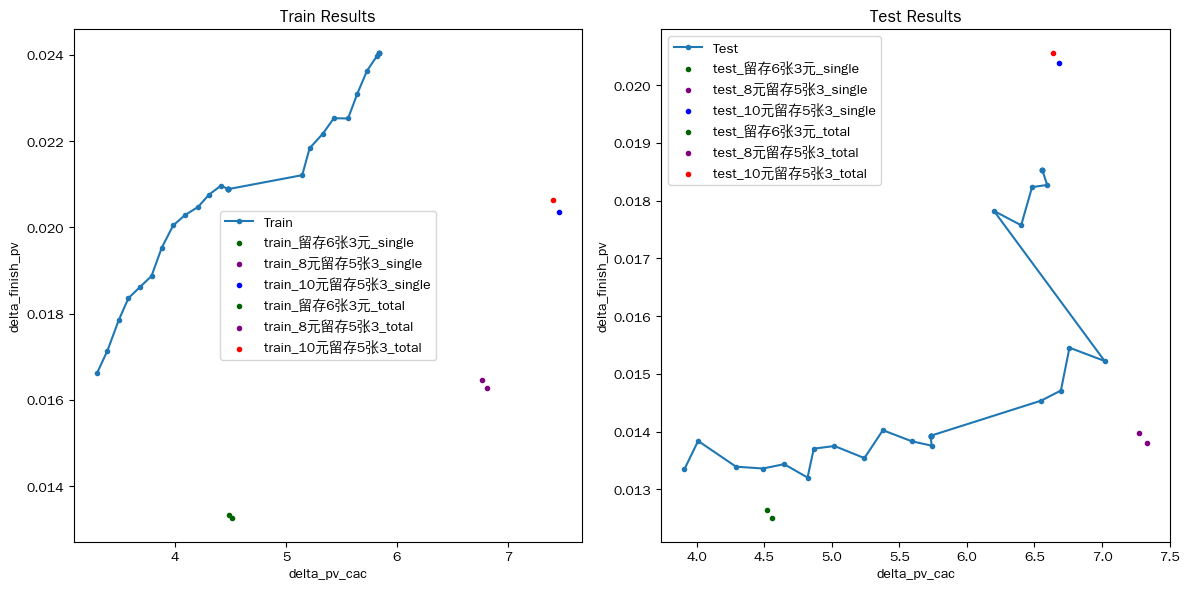


========== euen: running euen_v2 | s2 ==========
columns: ['cost_1', 'left1053', 'left853', 'left63']
all_columns: ['cost_1_per', 'left1053_per', 'left853_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']
(837501, 42) (843787, 42)


,cost_1_per,left1053_per,left853_per,left63_per,counts
0,0.1,0.1,0.1,0.1,40439
111,0.1,0.2,0.2,0.2,21183
1111,0.2,0.2,0.2,0.2,24086
1222,0.2,0.3,0.3,0.3,20925
2222,0.3,0.3,0.3,0.3,17985
2333,0.3,0.4,0.4,0.4,18835
3333,0.4,0.4,0.4,0.4,15123
3444,0.4,0.5,0.5,0.5,16798
4444,0.5,0.5,0.5,0.5,16328
4555,0.5,0.6,0.6,0.6,15549


['left1053_per', 'left853_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_per,left853_per,counts
0,0.1,0.1,28574
12,0.2,0.3,20660
23,0.3,0.4,22977
34,0.4,0.5,23631


['left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
0,0.1,16116
1,0.2,25920
2,0.3,24701
3,0.4,28171
4,0.5,36002
5,0.6,30626
6,0.7,26584
7,0.8,30340
8,0.9,22935



============================== Final Small Combinations ==============================
Small Combinations (<15000 samples):


,left63_per,counts
9,1.0,8958


[24  7 13 17 15 27  1 30  5 16 14 11 18 20 23  9 22 29 26  8  3 28 19  4
 12 10  0  2 25 21  6]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   5400        6.0       25.0      59.368   
1              0   8元留存5张3   5381       13.0       71.0      24.514   
2              0      DS空白  21810       35.0      106.0       0.000   
3              0    留存6张3元   7848       19.0      105.0      52.324   
4              1  10元留存5张3   2741        3.0        4.0      22.878   
..           ...       ...    ...        ...        ...         ...   
119           29    留存6张3元   4530       95.0      257.0     424.657   
120           30  10元留存5张3   1160       42.0      127.0     508.164   
121           30   8元留存5张3   1130       40.0       88.0     285.251   
122           30      DS空白   4897       82.0      234.0      30.000   
123           30    留存6张3元   1771       50.0      124.0     238.651   

     delta_cvr  delta_cac  
0    -0.

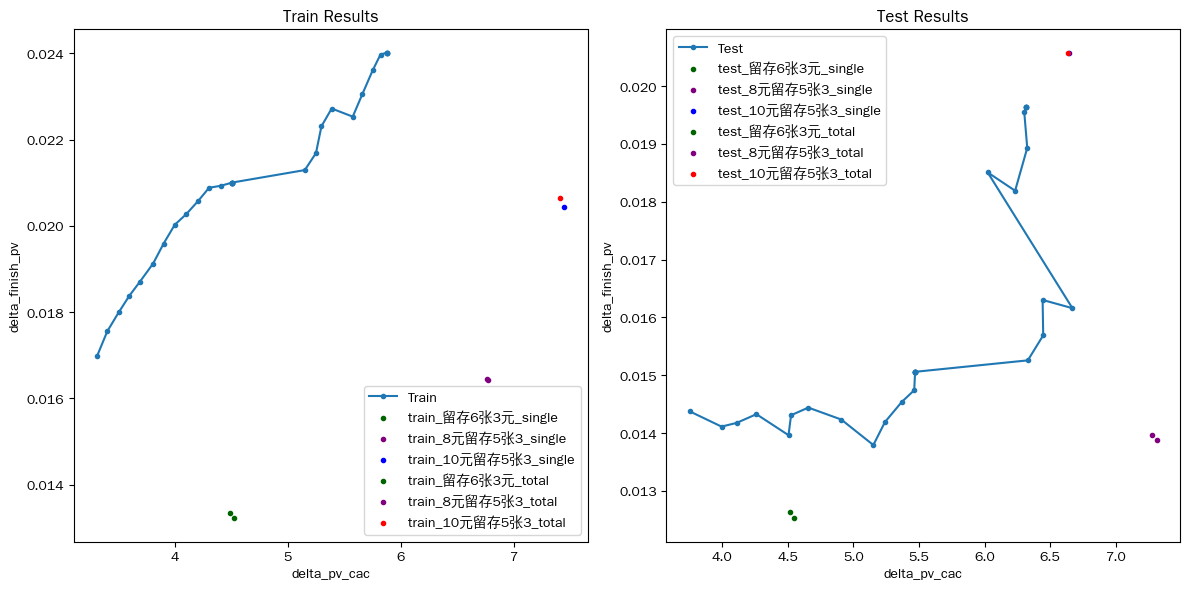


========== euen: running euen_v2 | s3 ==========
columns: ['cost_1', 'left1053_minus_left63', 'left853_minus_left63', 'left63']
all_columns: ['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '20

,cost_1_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
7777,0.8,0.8,0.8,0.8,24191
8888,0.9,0.9,0.9,0.9,46056
9999,1.0,1.0,1.0,1.0,67598


['left1053_minus_left63_per', 'left853_minus_left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_minus_left63_per,left853_minus_left63_per,counts
60,0.7,0.1,17602
67,0.7,0.8,15472
78,0.8,0.9,17944


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
0,0.1,77016
1,0.2,81825
2,0.3,82864
3,0.4,82563
4,0.5,82026
5,0.6,80995
6,0.7,77457
7,0.8,42547
8,0.9,25393



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
9,1.0,15952


[ 9 10  4  6 14 12  7  3  1 15 13  5  2 11  8  0]
rct_pred_data:     bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  delta_cvr  \
0             0  10元留存5张3   3033       32.0      100.0     350.074   0.019585   
1             0   8元留存5张3   3051       33.0       84.0     357.054   0.014146   
2             0      DS空白  13522       59.0      181.0       0.777        NaN   
3             0    留存6张3元   4585       48.0      153.0     344.339   0.019984   
4             1  10元留存5张3   5909      150.0      431.0    1660.349   0.048380   
..          ...       ...    ...        ...        ...         ...        ...   
59           14    留存6张3元   4973      134.0      340.0     510.631   0.028283   
60           15  10元留存5张3   2051       70.0      197.0     803.177   0.045358   
61           15   8元留存5张3   2103       80.0      211.0     700.275   0.049640   
62           15      DS空白   8660      147.0      439.0      30.000        NaN   
63           15    留存6张3元   3138      117.0 

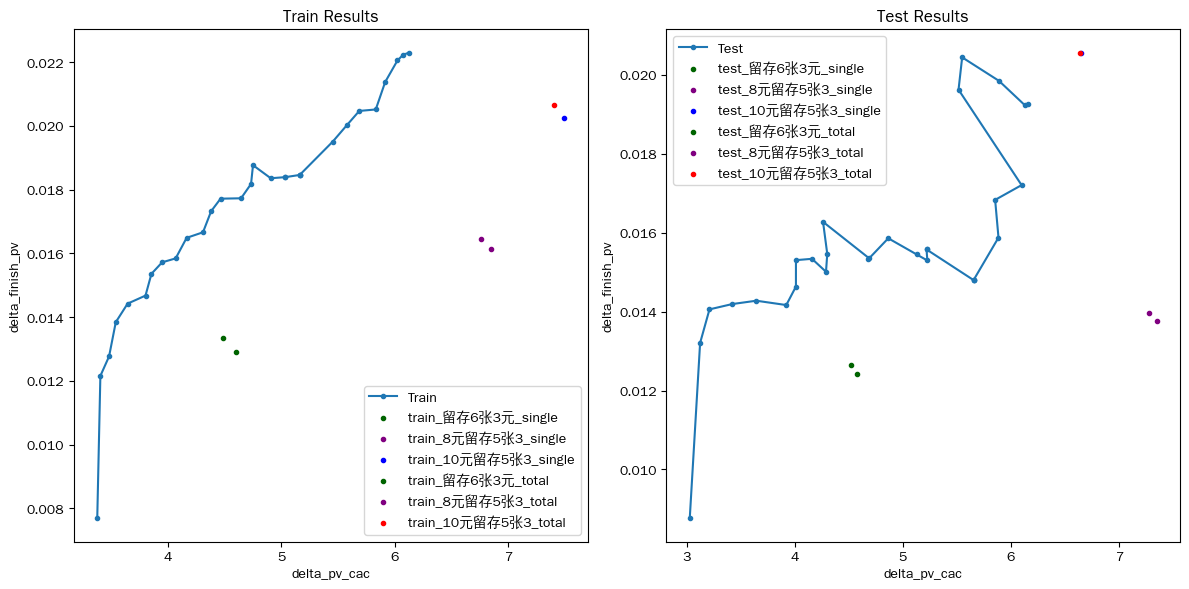


========== euen: running euen_v2 | s4 ==========
columns: ['cost_1', 'left1053_minus_left63', 'left853', 'left63']
all_columns: ['cost_1_per', 'left1053_minus_left63_per', 'left853_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']


,cost_1_per,left1053_minus_left63_per,left853_per,left63_per,counts
0,0.1,0.1,0.1,0.1,14005
100,0.1,0.2,0.1,0.1,10980
6666,0.7,0.7,0.7,0.7,19620
7677,0.8,0.7,0.8,0.8,16006
7777,0.8,0.8,0.8,0.8,38229
8788,0.9,0.8,0.9,0.9,14091
8888,0.9,0.9,0.9,0.9,50066
9999,1.0,1.0,1.0,1.0,68517


['left1053_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_minus_left63_per,left63_per,counts
1,0.1,0.2,13146
2,0.1,0.3,10432
3,0.1,0.4,10153
4,0.1,0.5,12792
5,0.1,0.6,14850
11,0.2,0.2,18127
12,0.2,0.3,14160
13,0.2,0.4,11418
14,0.2,0.5,10741
20,0.3,0.1,12391


['left1053_minus_left63_per', 'left853_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage
['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,46018
5,0.6,29702
6,0.7,27818



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
1,0.2,9441
2,0.3,11119
3,0.4,3723
4,0.5,6729
7,0.8,17577
8,0.9,19787
9,1.0,3723


[43 30  2 22 40 42 10  6 39  4  5  7 41 37 25 31 20  8 32 33 15 26 18 36
 38 17 19 35 27 24 28 16 34  3 12 29 23 11  0  9 13  1 14 21]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1934        1.0        6.0       6.491   
1              0   8元留存5张3   1876        4.0       21.0       4.258   
2              0      DS空白   7377        9.0       43.0       0.000   
3              0    留存6张3元   2818        6.0       41.0      34.131   
4              1  10元留存5张3   1458        0.0        0.0       5.193   
..           ...       ...    ...        ...        ...         ...   
171           42    留存6张3元   5426       56.0      167.0     288.465   
172           43  10元留存5张3   8921      191.0      513.0    1568.632   
173           43   8元留存5张3   9217      189.0      539.0    1117.303   
174           43      DS空白  39885      611.0     1731.0       5.162   
175           43    留存6张3元  14076      265.0      703.0     860.535  

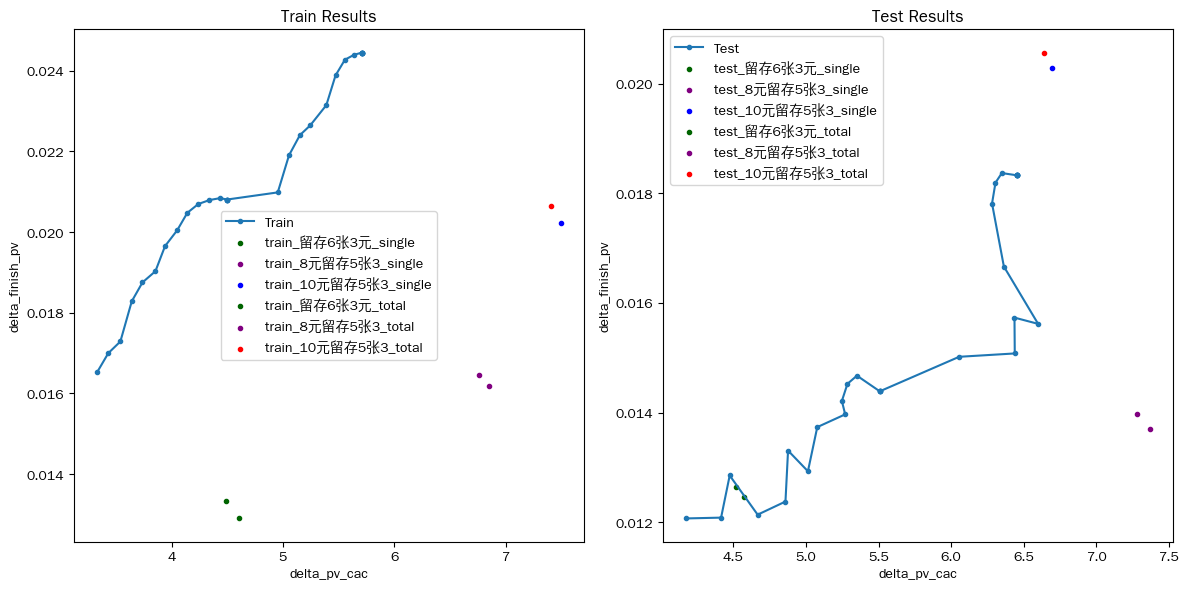


========== euen: running euen_v2 | s5 ==========
columns: ['cost_1', 'left1053', 'left63']
all_columns: ['cost_1_per', 'left1053_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']
(837501, 41) (843787, 41)
['cost_1_per', 'left1053_p

,cost_1_per,left1053_per,left63_per,counts
0,0.1,0.1,0.1,48312
11,0.1,0.2,0.2,26254
111,0.2,0.2,0.2,30812
122,0.2,0.3,0.3,27001
222,0.3,0.3,0.3,25005
233,0.3,0.4,0.4,23765
333,0.4,0.4,0.4,22757
344,0.4,0.5,0.5,21044
444,0.5,0.5,0.5,24318
455,0.5,0.6,0.6,20090


['left1053_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_per,left63_per,counts
0,0.1,0.1,27297
12,0.2,0.3,13288
23,0.3,0.4,16673
32,0.4,0.3,11215
34,0.4,0.5,18714
43,0.5,0.4,13167
54,0.6,0.5,12468
56,0.6,0.7,10803


['left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
1,0.2,26343
5,0.6,18780
6,0.7,10370
7,0.8,18484
8,0.9,22216



============================== Final Small Combinations ==============================
Small Combinations (<10000 samples):


,left63_per,counts
0,0.1,7785
2,0.3,7501
3,0.4,7518
4,0.5,7197
9,1.0,8828


[31  7 13 20 16 25  1 22  5 17 15 11  2 23  9 26 30 28  8  3 12 14 21  4
 10 29  0 24 19 18  6 27]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   6427        7.0       32.0      62.595   
1              0   8元留存5张3   6419       16.0       95.0      26.098   
2              0      DS空白  26118       37.0      115.0       0.000   
3              0    留存6张3元   9348       22.0      121.0      54.501   
4              1  10元留存5张3   3412        6.0       21.0      50.288   
..           ...       ...    ...        ...        ...         ...   
123           30    留存6张3元   4395       90.0      249.0     407.190   
124           31  10元留存5张3   4982      105.0      319.0     907.102   
125           31   8元留存5张3   4983       91.0      252.0     500.768   
126           31      DS空白  21266      294.0      975.0      60.021   
127           31    留存6张3元   7598      117.0      324.0     446.829   

     delta_cvr  delta_cac  
0    

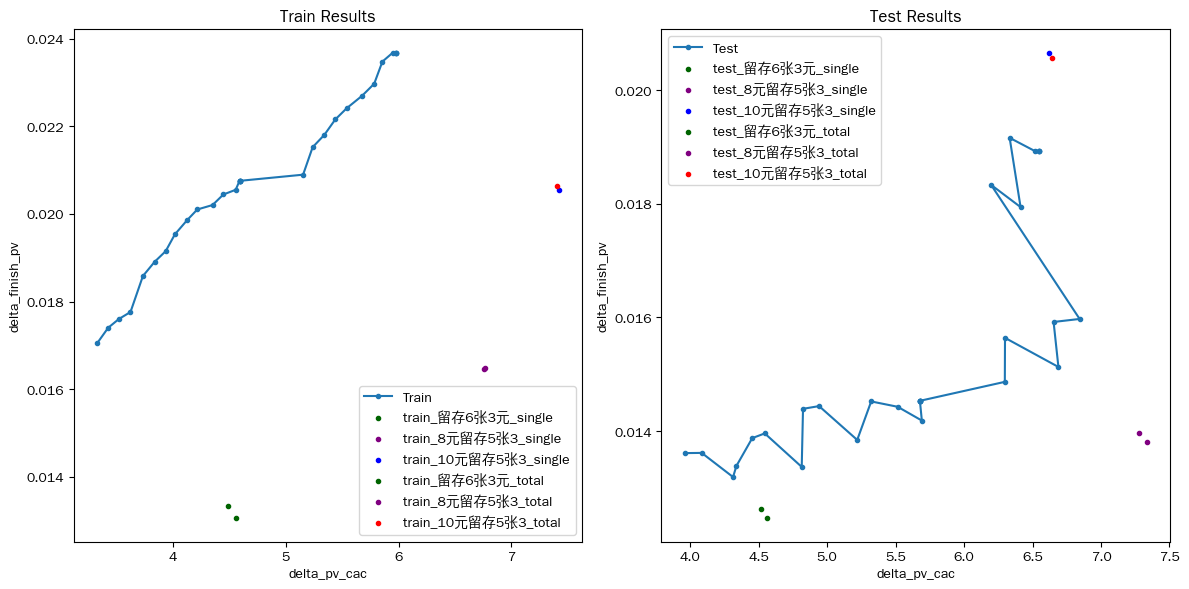


========== euen: running euen_v3 | s1 ==========
columns: ['cost_1', 'left1053', 'left853', 'left63']
all_columns: ['cost_1_per', 'left1053_per', 'left853_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']
(837501, 42) (843787, 42)


,cost_1_per,left1053_per,left853_per,left63_per,counts
0,0.1,0.1,0.1,0.1,53897
111,0.1,0.2,0.2,0.2,17056
1111,0.2,0.2,0.2,0.2,26134
1222,0.2,0.3,0.3,0.3,16293
2111,0.3,0.2,0.2,0.2,11433
2222,0.3,0.3,0.3,0.3,16996
2333,0.3,0.4,0.4,0.4,12399
3222,0.4,0.3,0.3,0.3,10231
3333,0.4,0.4,0.4,0.4,14928
3444,0.4,0.5,0.5,0.5,12066


['left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left853_per,left63_per,counts
0,0.1,0.1,22936
11,0.2,0.2,12793
12,0.2,0.3,10359
22,0.3,0.3,16020
23,0.3,0.4,13359
32,0.4,0.3,13341
33,0.4,0.4,26350
34,0.4,0.5,15371
43,0.5,0.4,15989
44,0.5,0.5,24609


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage

============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,6448
1,0.2,16235
2,0.3,551
3,0.4,896
4,0.5,1400
5,0.6,1570
6,0.7,10063
7,0.8,4928
8,0.9,7491
9,1.0,2075


[13  8 15  1 34 17 14  2 29 18 38 21 19 20 10 25 32 23 22  5 12 36 40 35
 31 26 27  7 11 16  0  9 28 33  4  3 30 37 24  6 39]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   7232        7.0       20.0      48.380   
1              0   8元留存5张3   7361       14.0      104.0      34.592   
2              0      DS空白  28959       24.0       76.0       0.000   
3              0    留存6张3元  10345        8.0       63.0      30.160   
4              1  10元留存5张3   2199        3.0       17.0      31.980   
..           ...       ...    ...        ...        ...         ...   
159           39    留存6张3元   2455       78.0      219.0     394.148   
160           40  10元留存5张3   6690      127.0      376.0     886.235   
161           40   8元留存5张3   6763       98.0      323.0     533.155   
162           40      DS空白  28162      330.0     1007.0      45.000   
163           40    留存6张3元  10042      140.0      394.0     433.410   

     d

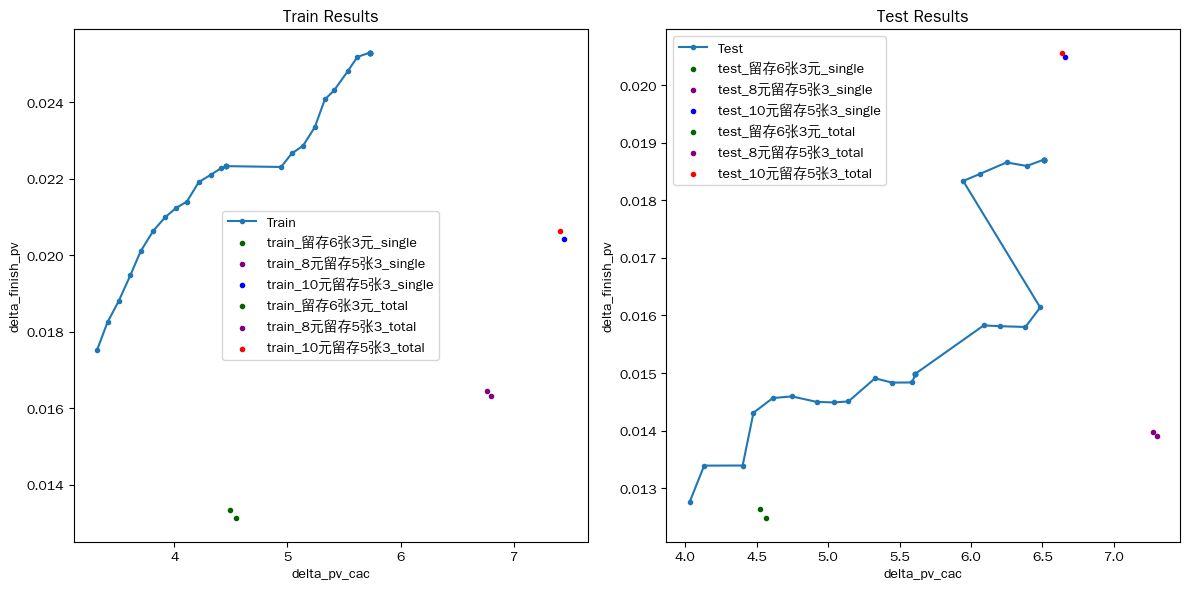


========== euen: running euen_v3 | s2 ==========
columns: ['cost_1', 'left1053', 'left853', 'left63']
all_columns: ['cost_1_per', 'left1053_per', 'left853_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']
(837501, 42) (843787, 42)


,cost_1_per,left1053_per,left853_per,left63_per,counts
0,0.1,0.1,0.1,0.1,53897
111,0.1,0.2,0.2,0.2,17056
1111,0.2,0.2,0.2,0.2,26134
1222,0.2,0.3,0.3,0.3,16293
2111,0.3,0.2,0.2,0.2,11433
2222,0.3,0.3,0.3,0.3,16996
2333,0.3,0.4,0.4,0.4,12399
3222,0.4,0.3,0.3,0.3,10231
3333,0.4,0.4,0.4,0.4,14928
3444,0.4,0.5,0.5,0.5,12066


['left1053_per', 'left853_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_per,left853_per,counts
0,0.1,0.1,21591
23,0.3,0.4,19183
33,0.4,0.4,18447
34,0.4,0.5,23025
45,0.5,0.6,24234
54,0.6,0.5,16234
56,0.6,0.7,21456
65,0.7,0.6,16694
67,0.7,0.8,18225
76,0.8,0.7,15757


['left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
1,0.2,27123
2,0.3,26889
3,0.4,19373
4,0.5,27101
5,0.6,16289
7,0.8,19922
8,0.9,24369



============================== Final Small Combinations ==============================
Small Combinations (<15000 samples):


,left63_per,counts
0,0.1,9286
6,0.7,13044
9,1.0,14402


[13  8 15  1 26 17 14  2 33 18 36 37 19 30 10 21 24 31  5 12 35 27 34 22
 23  7 11 16 28  0  9  4 32 25 29  3  6 20]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   7232        7.0       20.0      48.380   
1              0   8元留存5张3   7361       14.0      104.0      34.592   
2              0      DS空白  28959       24.0       76.0       0.000   
3              0    留存6张3元  10345        8.0       63.0      30.160   
4              1  10元留存5张3   2199        3.0       17.0      31.980   
..           ...       ...    ...        ...        ...         ...   
147           36    留存6张3元   4870      144.0      356.0     447.847   
148           37  10元留存5张3   4661      119.0      348.0    1094.441   
149           37   8元留存5张3   4738      122.0      332.0     817.569   
150           37      DS空白  20140      314.0      921.0      85.172   
151           37    留存6张3元   7193      141.0      403.0     619.847   

     delta_cvr 

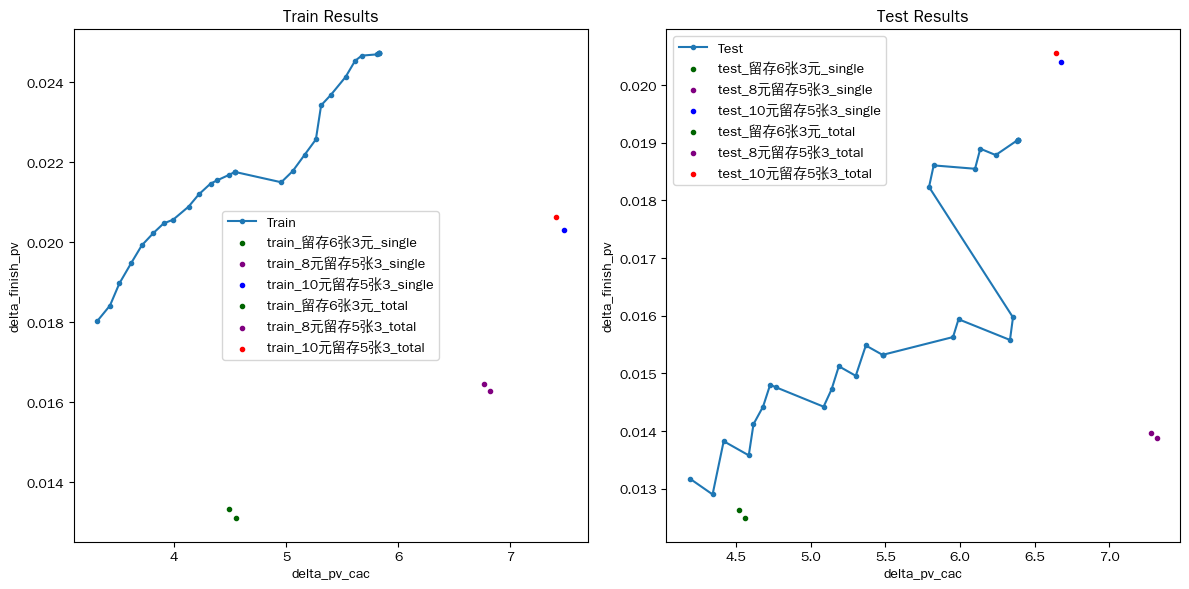


========== euen: running euen_v3 | s3 ==========
columns: ['cost_1', 'left1053_minus_left63', 'left853_minus_left63', 'left63']
all_columns: ['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '20

,cost_1_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,0.1,38473
9999,1.0,1.0,1.0,1.0,55271


['left1053_minus_left63_per', 'left853_minus_left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_minus_left63_per,left853_minus_left63_per,counts
1,0.1,0.2,23887
11,0.2,0.2,19194
12,0.2,0.3,23237
13,0.2,0.4,18232
23,0.3,0.4,16836
24,0.3,0.5,17451
35,0.4,0.6,16165
46,0.5,0.7,15244
77,0.8,0.8,16487
78,0.8,0.9,21145


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
0,0.1,24442
1,0.2,29504
2,0.3,47372
3,0.4,64310
4,0.5,69763
5,0.6,78318
6,0.7,83187
7,0.8,63918
8,0.9,32831



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
9,1.0,15252


[20 17 10  3 11 18 13 22 15  4  1 12  2 16 19 21  5 14  8 23  7  0  6  9]
rct_pred_data:     bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  delta_cvr  \
0             0  10元留存5张3   5081        5.0       11.0      26.546  -0.000105   
1             0   8元留存5张3   5275       10.0       75.0      29.556   0.011948   
2             0      DS空白  20708       14.0       47.0       0.000        NaN   
3             0    留存6张3元   7409        7.0       56.0      22.747   0.005289   
4             1  10元留存5张3   7387      735.0     2128.0    7185.897   0.152439   
..          ...       ...    ...        ...        ...         ...        ...   
91           22    留存6张3元   6595      191.0      504.0     721.540   0.029333   
92           23  10元留存5张3   1913       89.0      242.0     778.980   0.069687   
93           23   8元留存5张3   2086       87.0      206.0     623.372   0.041938   
94           23      DS空白   8202      184.0      466.0       0.000        NaN   
95           23    留

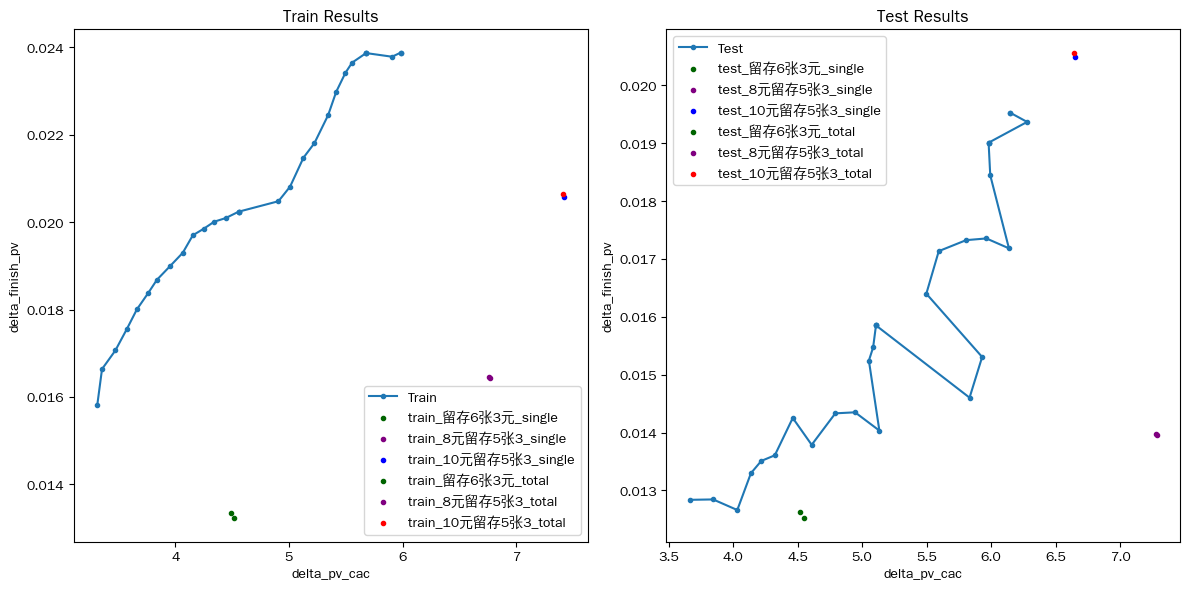


========== euen: running euen_v3 | s4 ==========
columns: ['cost_1', 'left1053_minus_left63', 'left853', 'left63']
all_columns: ['cost_1_per', 'left1053_minus_left63_per', 'left853_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']


,cost_1_per,left1053_minus_left63_per,left853_per,left63_per,counts
0,0.1,0.1,0.1,0.1,52504
111,0.1,0.2,0.2,0.2,13580
1111,0.2,0.2,0.2,0.2,20853
1222,0.2,0.3,0.3,0.3,11316
2222,0.3,0.3,0.3,0.3,12660
3333,0.4,0.4,0.4,0.4,11717
4444,0.5,0.5,0.5,0.5,12536
5555,0.6,0.6,0.6,0.6,14739
6666,0.7,0.7,0.7,0.7,17901
7777,0.8,0.8,0.8,0.8,22469


['left1053_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_minus_left63_per,left63_per,counts
0,0.1,0.1,15624
1,0.1,0.2,15224
11,0.2,0.2,24622
12,0.2,0.3,19515
22,0.3,0.3,29539
23,0.3,0.4,21202
33,0.4,0.4,39003
34,0.4,0.5,22219
43,0.5,0.4,10554
44,0.5,0.5,35824


['left1053_minus_left63_per', 'left853_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage
['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================

No Large Combinations in this stage

============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,15153
1,0.2,9372
2,0.3,10761
3,0.4,1445
4,0.5,1277
5,0.6,1285
6,0.7,2711
7,0.8,2656
8,0.9,11604
9,1.0,10617


[29  5 32  1 27 36  8  2 23 11 35 13 14  6 12 18 24 17  7 34 28 20 26 33
  9 19 10  0 25 16 31  3 22  4 21 15 30]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   7066        7.0       20.0      47.733   
1              0   8元留存5张3   7161       14.0      104.0      34.361   
2              0      DS空白  28191       22.0       72.0       0.000   
3              0    留存6张3元  10086        8.0       63.0      29.647   
4              1  10元留存5张3   1760        3.0       17.0      30.781   
..           ...       ...    ...        ...        ...         ...   
143           35    留存6张3元   2593      107.0      237.0     244.528   
144           36  10元留存5张3   8628      209.0      621.0    1538.636   
145           36   8元留存5张3   8778      208.0      612.0    1130.694   
146           36      DS空白  36155      705.0     2287.0     100.042   
147           36    留存6张3元  13320      254.0      784.0     789.946   

     delta_cvr  de

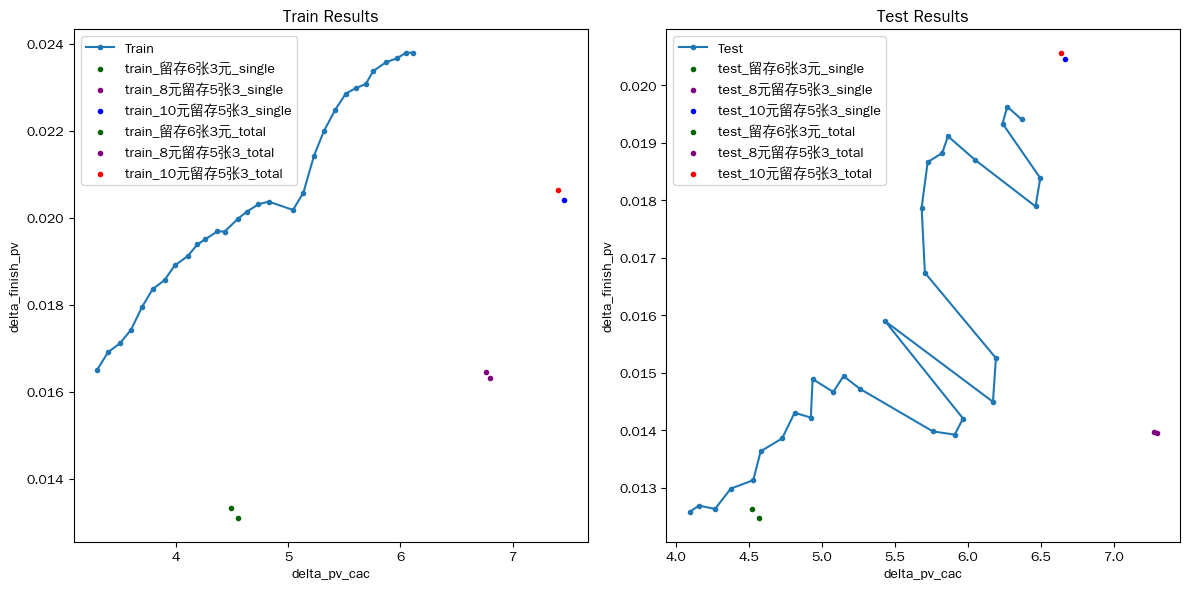


========== euen: running euen_v3 | s5 ==========
columns: ['cost_1', 'left1053', 'left63']
all_columns: ['cost_1_per', 'left1053_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']
(837501, 41) (843787, 41)
['cost_1_per', 'left1053_p

,cost_1_per,left1053_per,left63_per,counts
0,0.1,0.1,0.1,56104
11,0.1,0.2,0.2,19770
100,0.2,0.1,0.1,10793
111,0.2,0.2,0.2,32008
122,0.2,0.3,0.3,22745
211,0.3,0.2,0.2,13781
222,0.3,0.3,0.3,23640
233,0.3,0.4,0.4,20852
322,0.4,0.3,0.3,13158
333,0.4,0.4,0.4,21651


['left1053_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_per,left63_per,counts
0,0.1,0.1,10447
33,0.4,0.4,10800
34,0.4,0.5,10566
45,0.5,0.6,11794
56,0.6,0.7,11423
67,0.7,0.8,10463
77,0.8,0.8,10984


['left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
1,0.2,18092
2,0.3,24248
3,0.4,17254
4,0.5,19036
5,0.6,16672
6,0.7,13683
8,0.9,20483
9,1.0,14359



============================== Final Small Combinations ==============================
Small Combinations (<10000 samples):


,left63_per,counts
0,0.1,5937
7,0.8,6387


[16  9 19  1 29 22 18  3 35 23 38 40 24 32 12  4 27 33  6 15 20 36 11  8
 14 13 21 34  0 10  5  7 31 37 17 25 39 26  2 28 30]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   7533        7.0       20.0      49.286   
1              0   8元留存5张3   7644       15.0      105.0      34.928   
2              0      DS空白  30167       27.0       97.0       0.000   
3              0    留存6张3元  10760        8.0       63.0      31.076   
4              1  10元留存5张3   2571        4.0       18.0      43.647   
..           ...       ...    ...        ...        ...         ...   
159           39    留存6张3元   2845       86.0      243.0     465.426   
160           40  10元留存5张3   1600       44.0      114.0     301.726   
161           40   8元留存5张3   1619       47.0      103.0     147.847   
162           40      DS空白   6598      189.0      541.0      75.000   
163           40    留存6张3元   2507       58.0      158.0     137.015   

     d

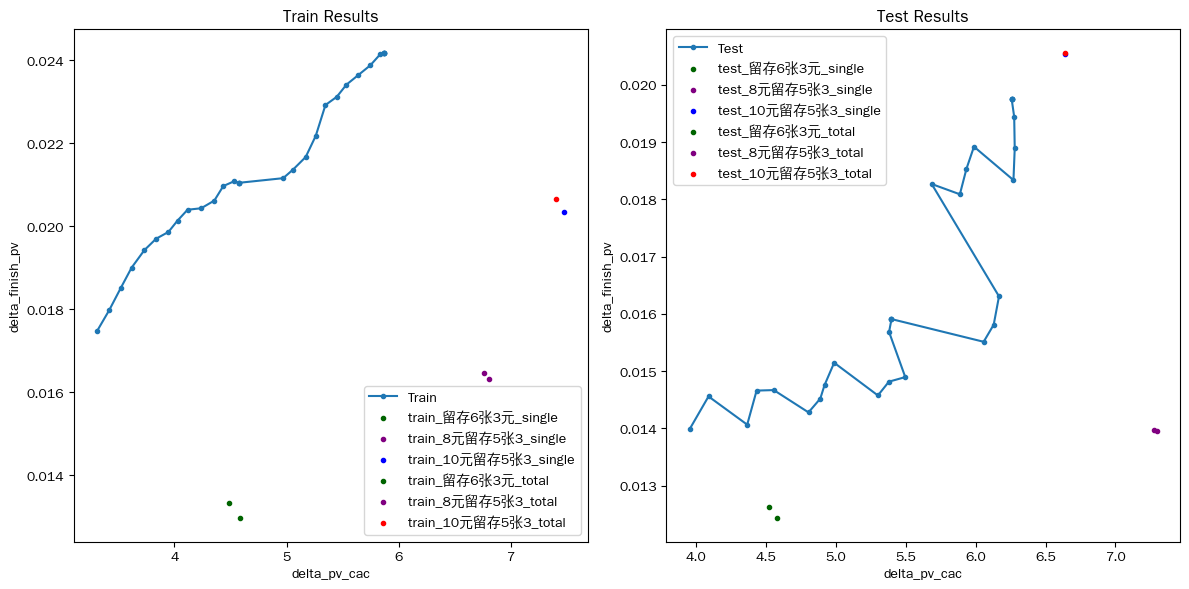


========== eeuen: running eeuen_v2 | s1 ==========
columns: ['exposure_prob', 'left1053_minus_left63', 'left853_minus_left63', 'left63']
all_columns: ['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '

,exposure_prob_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
8999,0.9,1.0,1.0,1.0,15994


['exposure_prob_per', 'left1053_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,exposure_prob_per,left1053_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,42267
999,1.0,1.0,1.0,18302


['exposure_prob_per', 'left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,exposure_prob_per,left853_minus_left63_per,left63_per,counts
111,0.2,0.2,0.2,15259
908,1.0,0.1,0.9,25676


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,40500
1,0.2,68498
2,0.3,83774
3,0.4,83929
4,0.5,84064
5,0.6,84064
6,0.7,83838
7,0.8,83904
8,0.9,58056
9,1.0,49376



============================== Final Small Combinations ==============================

No Small Combinations in final stage
[ 9 11  5  7 12  8  0 14  1  4  2 10  6 13  3]
rct_pred_data:     bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  delta_cvr  \
0             0  10元留存5张3   2043      203.0      623.0    2009.173   0.196076   
1             0   8元留存5张3   2156      192.0      544.0    1566.983   0.143451   
2             0      DS空白   8570      344.0      933.0      55.000        NaN   
3             0    留存6张3元   3225      262.0      730.0    1101.151   0.117488   
4             1  10元留存5张3   6413       26.0       96.0     112.744  -0.013796   
5             1   8元留存5张3   6001       37.0      125.0      54.248  -0.007936   
6             1      DS空白  20858      135.0      600.0       0.000        NaN   
7             1    留存6张3元   8995       45.0      182.0      79.483  -0.008532   
8             2  10元留存5张3   2386      258.0      687.0    2730.657   0.193453   
9 

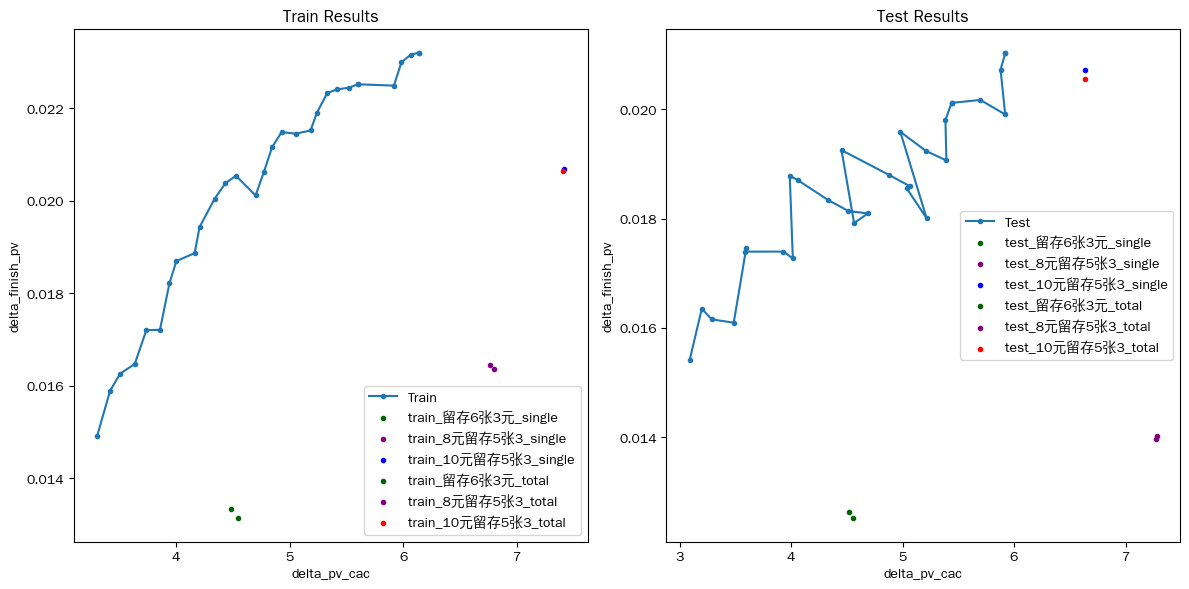


========== eeuen: running eeuen_v2 | s2 ==========
columns: ['exposure_prob', 'left1053', 'left853', 'left63']
all_columns: ['exposure_prob_per', 'left1053_per', 'left853_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']
(837501, 4

,exposure_prob_per,left1053_per,left853_per,left63_per,counts
0,0.1,0.1,0.1,0.1,42798
1111,0.2,0.2,0.2,0.2,16097
8999,0.9,1.0,1.0,1.0,23118
9888,1.0,0.9,0.9,0.9,15574
9999,1.0,1.0,1.0,1.0,34672


['exposure_prob_per', 'left853_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,exposure_prob_per,left853_per,left63_per,counts
11,0.1,0.2,0.2,16736
100,0.2,0.1,0.1,15634
222,0.3,0.3,0.3,23408
333,0.4,0.4,0.4,24145
433,0.5,0.4,0.4,15627
444,0.5,0.5,0.5,24491
544,0.6,0.5,0.5,18433
555,0.6,0.6,0.6,23300
655,0.7,0.6,0.6,18142
666,0.7,0.7,0.7,20250


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
0,0.1,24335
1,0.2,50924
2,0.3,60366
3,0.4,44157
4,0.5,41140
5,0.6,42622
6,0.7,47773
7,0.8,63250
8,0.9,29253
9,1.0,25882



============================== Final Small Combinations ==============================

No Small Combinations in final stage
[23 14 19 20 26 10  8  2 28  5  3  4 12 13 21 24  9 18 11 22 16  6  7 25
 15  0 17  1 27]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   6290       35.0      115.0     154.357   
1              0   8元留存5张3   5930       41.0      159.0     106.856   
2              0      DS空白  21594      193.0      867.0       0.000   
3              0    留存6张3元   8984       51.0      207.0     118.108   
4              1  10元留存5张3   2006        7.0       30.0      39.326   
..           ...       ...    ...        ...        ...         ...   
111           27    留存6张3元   5805      164.0      409.0     699.229   
112           28  10元留存5张3   3374      196.0      545.0    1758.525   
113           28   8元留存5张3   3416      180.0      427.0    1388.032   
114           28      DS空白  13792      381.0     1073.0    

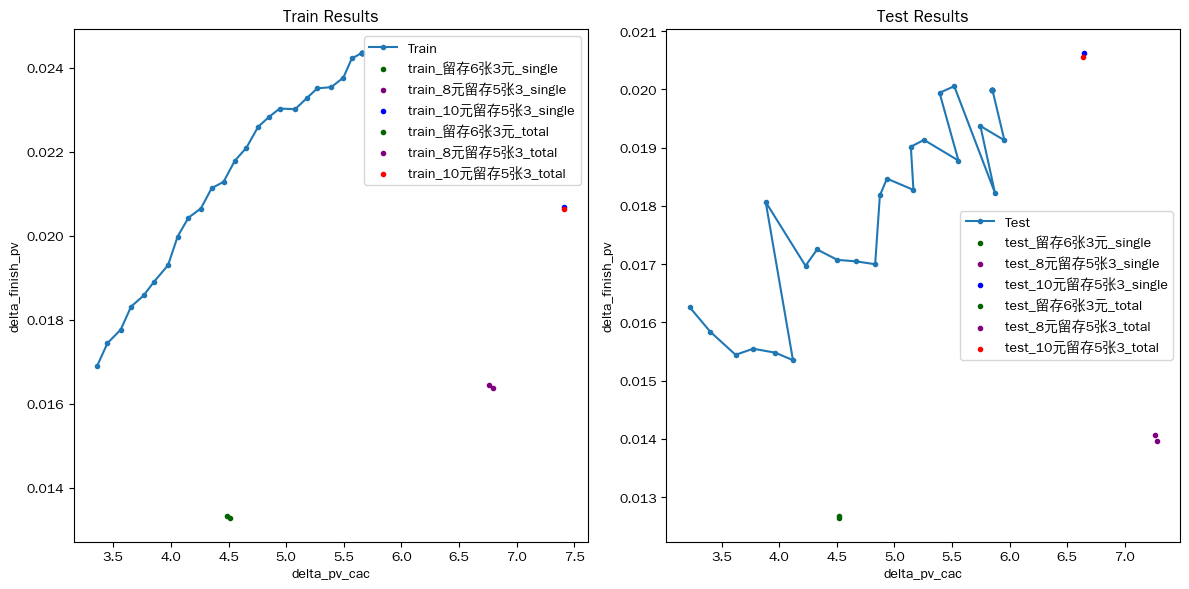


========== eeuen: running eeuen_v2 | s3 ==========
columns: ['cost_1', 'left1053_minus_left853', 'left853_minus_left63', 'left63']
all_columns: ['cost_1_per', 'left1053_minus_left853_per', 'left853_minus_left63_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28',

,cost_1_per,left1053_minus_left853_per,left853_minus_left63_per,left63_per,counts
9999,1.0,1.0,1.0,1.0,32162


['cost_1_per', 'left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left853_minus_left63_per,left63_per,counts
11,0.1,0.2,0.2,20503
707,0.8,0.1,0.8,16977
808,0.9,0.1,0.9,23897
898,0.9,1.0,0.9,16351
909,1.0,0.1,1.0,15721


['left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
1,0.2,38948
2,0.3,26162
3,0.4,29378
4,0.5,37524
5,0.6,29479
6,0.7,32945
7,0.8,39798
8,0.9,43484
9,1.0,20677



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,14216


[28 21 25  1 13 23 16 24  3 20 18 29 19  0 26 27 32 31 15 12 34  6 30 10
 33  2 22 14  7  9 17  5  8  4 11]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   4226      491.0     1363.0    4730.212   
1              0   8元留存5张3   4400      456.0     1197.0    3586.316   
2              0      DS空白  16881      860.0     2270.0      60.000   
3              0    留存6张3元   6655      638.0     1588.0    2383.816   
4              1  10元留存5张3   2704        2.0        8.0      11.533   
..           ...       ...    ...        ...        ...         ...   
135           33    留存6张3元   4097      155.0      409.0     827.211   
136           34  10元留存5张3   1869       71.0      213.0     338.249   
137           34   8元留存5张3   1897       53.0      153.0     221.450   
138           34      DS空白   7385      340.0     1177.0      60.000   
139           34    留存6张3元   3065      113.0      333.0     241.260   

     delta_cvr  delta_ca

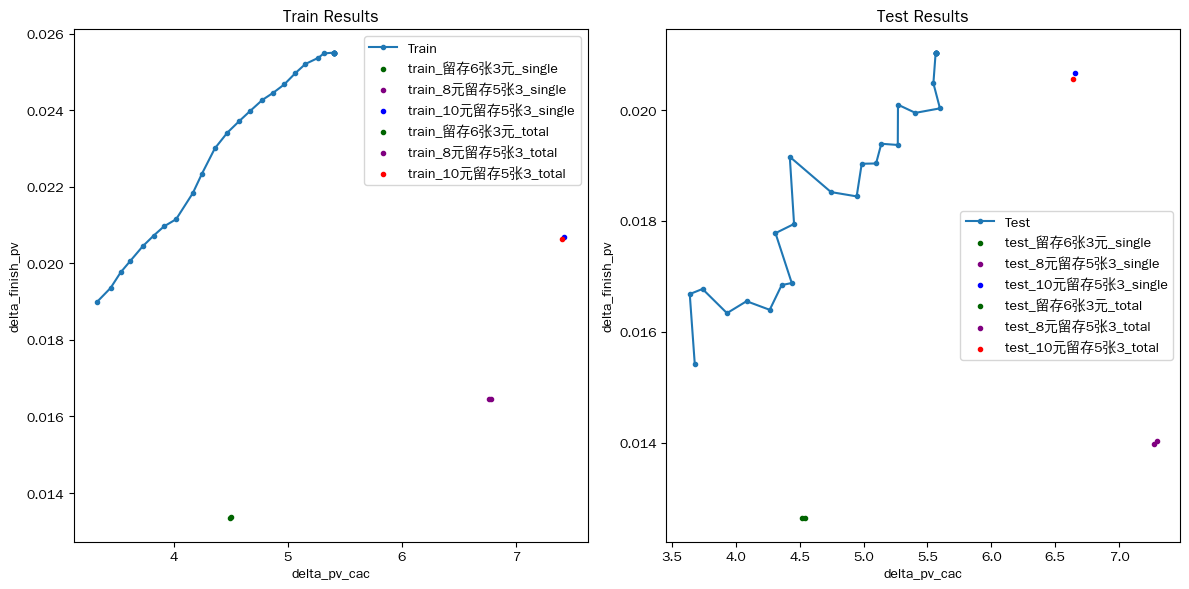


========== eeuen: running eeuen_v2 | s4 ==========
columns: ['cost_1', 'left1053_minus_left63', 'left853', 'left63']
all_columns: ['cost_1_per', 'left1053_minus_left63_per', 'left853_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06'

,cost_1_per,left1053_minus_left63_per,left853_per,left63_per,counts
0,0.1,0.1,0.1,0.1,22378
111,0.1,0.2,0.2,0.2,10206
8888,0.9,0.9,0.9,0.9,10978
9899,1.0,0.9,1.0,1.0,14984
9999,1.0,1.0,1.0,1.0,42990


['left1053_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_minus_left63_per,left63_per,counts
0,0.1,0.1,23010
1,0.1,0.2,14271
10,0.2,0.1,18172
11,0.2,0.2,19006
12,0.2,0.3,11161
21,0.3,0.2,21855
22,0.3,0.3,19611
23,0.3,0.4,10121
31,0.4,0.2,10449
32,0.4,0.3,22670


['left1053_minus_left63_per', 'left853_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage
['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
5,0.6,32659
6,0.7,41623
7,0.8,54352
8,0.9,41838
9,1.0,25698



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,19207
1,0.2,7970
2,0.3,13337
3,0.4,8589
4,0.5,19283


[39 29  8 31 21 18 13 38  6  3 32  4 25 23 26 24 22 11 34 17 37 30 19 35
  9 20 36 15 27 16 14  7 33  5  0 10 28 12  1  2]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   3303        5.0       10.0       6.827   
1              0   8元留存5张3   3050        9.0       40.0       5.038   
2              0      DS空白  11404       21.0      103.0       0.000   
3              0    留存6张3元   4621        7.0       36.0       7.413   
4              1  10元留存5张3   1338        2.0       18.0      29.658   
..           ...       ...    ...        ...        ...         ...   
155           38    留存6张3元   5173      179.0      487.0     987.352   
156           39  10元留存5张3   8567      136.0      398.0     830.831   
157           39   8元留存5张3   8700      113.0      405.0     578.380   
158           39      DS空白  37745      608.0     2098.0      65.021   
159           39    留存6张3元  13374      177.0      539.0     408.809   

     delt

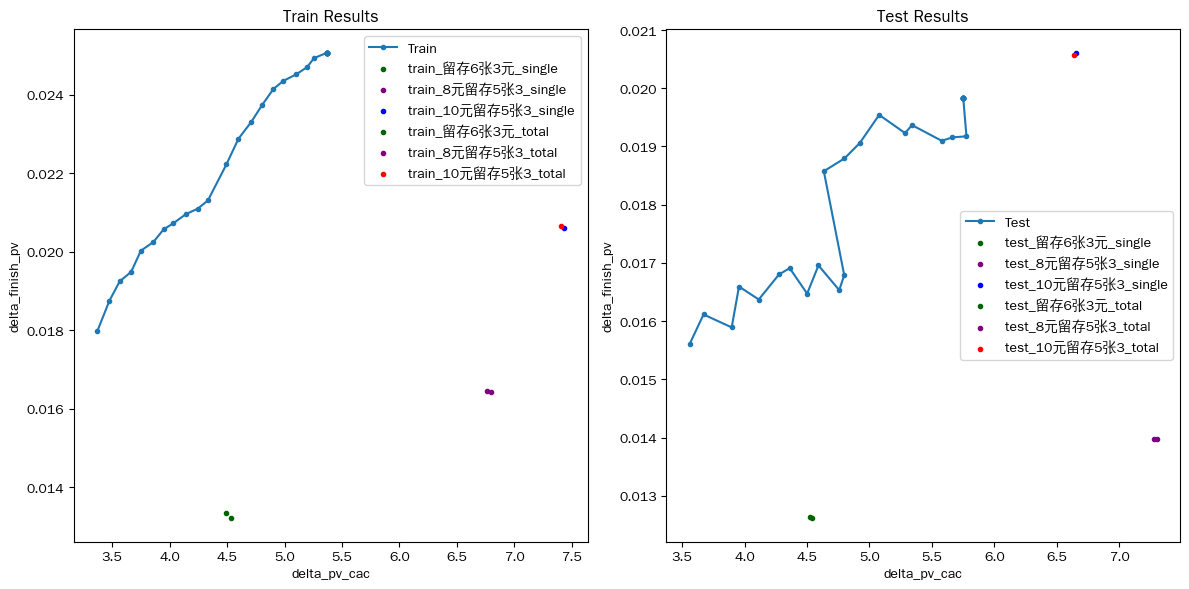


========== eeuen: running eeuen_v2 | s5 ==========
columns: ['cost_1', 'left1053', 'left63']
all_columns: ['cost_1_per', 'left1053_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']
(837501, 46) (843787, 46)
['cost_1_per', 'left1053

,cost_1_per,left1053_per,left63_per,counts
0,0.1,0.1,0.1,31957
1,0.1,0.1,0.2,13595
11,0.1,0.2,0.2,22871
111,0.2,0.2,0.2,14287
122,0.2,0.3,0.3,21161
233,0.3,0.4,0.4,17366
344,0.4,0.5,0.5,15357
444,0.5,0.5,0.5,10306
455,0.5,0.6,0.6,14601
555,0.6,0.6,0.6,12006


['left1053_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_per,left63_per,counts
0,0.1,0.1,30314
10,0.2,0.1,13810
12,0.2,0.3,20477
21,0.3,0.2,13737
22,0.3,0.3,21910
23,0.3,0.4,20585
32,0.4,0.3,16369
33,0.4,0.4,22391
34,0.4,0.5,19564
43,0.5,0.4,17888


['left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
1,0.2,19267
5,0.6,18804
6,0.7,16549
7,0.8,19105
8,0.9,10616



============================== Final Small Combinations ==============================
Small Combinations (<10000 samples):


,left63_per,counts
0,0.1,6686
2,0.3,3857
3,0.4,5699
4,0.5,7043
9,1.0,6238


[44 10 39 22 20 15  7 27  0 38 30 18 19  9 31 33 23  8 26 16 43 32  6 36
 12 21 40 41 42 34 14 35 13 25  1 28 29 11  2  5  4 24 37 17  3]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   4606        5.0       10.0       9.610   
1              0   8元留存5张3   4353       14.0       52.0       9.815   
2              0      DS空白  16448       34.0      144.0       0.000   
3              0    留存6张3元   6550       14.0       53.0      19.217   
4              1  10元留存5张3   1750        0.0        0.0       5.172   
..           ...       ...    ...        ...        ...         ...   
175           43    留存6张3元   2097       33.0       76.0     219.555   
176           44  10元留存5张3   3660      113.0      344.0     848.542   
177           44   8元留存5张3   3720      115.0      355.0     734.093   
178           44      DS空白  16265      401.0     1273.0      70.000   
179           44    留存6张3元   5878      166.0      453.0     488.39

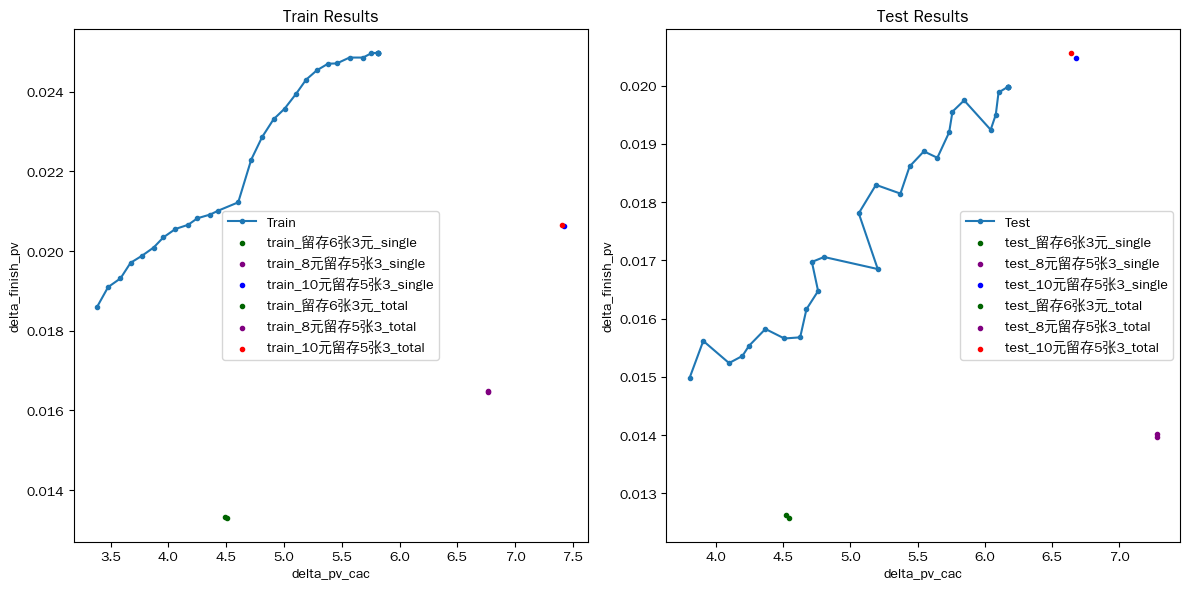


========== eeuen: running eeuen_v3 | s1 ==========
columns: ['exposure_prob', 'left1053_minus_left63', 'left853_minus_left63', 'left63']
all_columns: ['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '

,exposure_prob_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
8999,0.9,1.0,1.0,1.0,18773
9999,1.0,1.0,1.0,1.0,18491


['exposure_prob_per', 'left1053_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,exposure_prob_per,left1053_minus_left63_per,left63_per,counts
1,0.1,0.1,0.2,16547
2,0.1,0.1,0.3,20654
545,0.6,0.5,0.6,16482
656,0.7,0.6,0.7,18691
767,0.8,0.7,0.8,17298
877,0.9,0.8,0.8,16418
988,1.0,0.9,0.9,24370
989,1.0,0.9,1.0,18001


['exposure_prob_per', 'left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage
['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,83430
1,0.2,66627
2,0.3,63145
3,0.4,84046
4,0.5,84012
5,0.6,67417
6,0.7,65218
7,0.8,50027
8,0.9,59469
9,1.0,28385



============================== Final Small Combinations ==============================

No Small Combinations in final stage
[12 15 13 10 17  0 19 11  2  9  1 16 14  8  7  6 18  5  4  3]
rct_pred_data:     bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  delta_cvr  \
0             0  10元留存5张3   2432      246.0      705.0    2498.360   0.183248   
1             0   8元留存5张3   2558      209.0      578.0    1770.844   0.119321   
2             0      DS空白   9959      366.0     1062.0      80.000        NaN   
3             0    留存6张3元   3824      301.0      905.0    1356.549   0.130026   
4             1  10元留存5张3   2500      277.0      777.0    3018.272   0.210019   
..          ...       ...    ...        ...        ...         ...        ...   
75           18    留存6张3元  11588      261.0      694.0    1175.778   0.030676   
76           19  10元留存5张3   3752      279.0      829.0    2449.342   0.101570   
77           19   8元留存5张3   3749      268.0      697.0    1828.818  

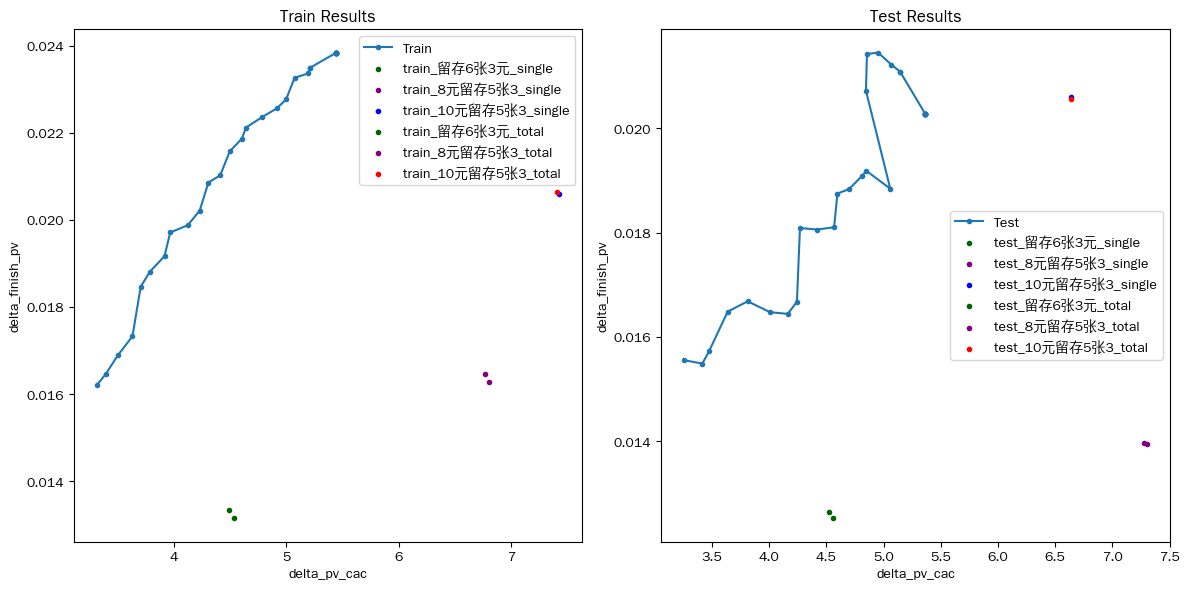


========== eeuen: running eeuen_v3 | s2 ==========
columns: ['exposure_prob', 'left1053', 'left853', 'left63']
all_columns: ['exposure_prob_per', 'left1053_per', 'left853_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']
(837501, 4

,exposure_prob_per,left1053_per,left853_per,left63_per,counts
0,0.1,0.1,0.1,0.1,16915
1000,0.2,0.1,0.1,0.1,17839
2000,0.3,0.1,0.1,0.1,15580
5555,0.6,0.6,0.6,0.6,15116
8777,0.9,0.8,0.8,0.8,16581
8888,0.9,0.9,0.9,0.9,15051
8999,0.9,1.0,1.0,1.0,21314
9888,1.0,0.9,0.9,0.9,26946
9999,1.0,1.0,1.0,1.0,28799


['exposure_prob_per', 'left853_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,exposure_prob_per,left853_per,left63_per,counts
11,0.1,0.2,0.2,17768
22,0.1,0.3,0.3,19056
111,0.2,0.2,0.2,16255
444,0.5,0.5,0.5,19510
666,0.7,0.7,0.7,22454
677,0.7,0.8,0.8,16036
766,0.8,0.7,0.7,17132
777,0.8,0.8,0.8,21187
788,0.8,0.9,0.9,15472


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
0,0.1,33096
1,0.2,49151
2,0.3,64743
3,0.4,84046
4,0.5,64502
5,0.6,68783
6,0.7,44323
7,0.8,29939
8,0.9,26370
9,1.0,33537



============================== Final Small Combinations ==============================

No Small Combinations in final stage
[18 23 19  1 14  9  6 27 21  8  2 24 22 13 12  4  7 25 15  3  5 11 26 20
 16 10  0 17]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   2643       33.0      110.0     103.670   
1              0   8元留存5张3   2473       45.0      150.0      75.192   
2              0      DS空白   7979      176.0      726.0      25.000   
3              0    留存6张3元   3820       45.0      143.0      73.127   
4              1  10元留存5张3   2448       30.0      106.0     178.018   
..           ...       ...    ...        ...        ...         ...   
107           26    留存6张3元   5248      135.0      370.0     567.734   
108           27  10元留存5张3   4457      296.0      848.0    2692.398   
109           27   8元留存5张3   4411      282.0      729.0    2044.643   
110           27      DS空白  17927      697.0     1809.0      6

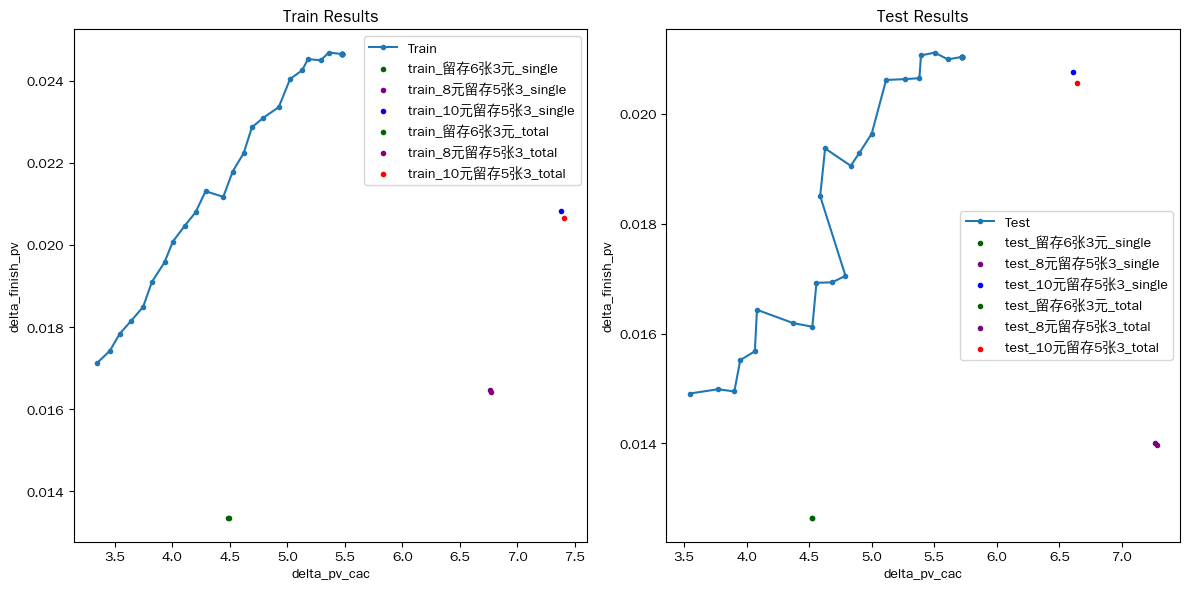


========== eeuen: running eeuen_v3 | s3 ==========
columns: ['cost_1', 'left1053_minus_left853', 'left853_minus_left63', 'left63']
all_columns: ['cost_1_per', 'left1053_minus_left853_per', 'left853_minus_left63_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28',

,cost_1_per,left1053_minus_left853_per,left853_minus_left63_per,left63_per,counts
9999,1.0,1.0,1.0,1.0,46644


['cost_1_per', 'left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left853_minus_left63_per,left63_per,counts
12,0.1,0.2,0.3,16638
777,0.8,0.8,0.8,18173
888,0.9,0.9,0.9,32551
999,1.0,1.0,1.0,16913


['left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,51331
1,0.2,33941
2,0.3,48743
3,0.4,64302
4,0.5,63914
5,0.6,58162
6,0.7,47927
9,1.0,20093



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
7,0.8,14719
8,0.9,15863


[22 26 11 23 21 17  0 28 24  4 10 15 25 13  8 12  2 19 29 16 27  3  9 20
 18  7  1  5  6 14]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   6238      658.0     1943.0    6609.632   
1              0   8元留存5张3   6353      611.0     1718.0    4898.486   
2              0      DS空白  24408     1214.0     3381.0     175.000   
3              0    留存6张3元   9645      888.0     2416.0    3488.457   
4              1  10元留存5张3   2235        3.0        7.0       5.517   
..           ...       ...    ...        ...        ...         ...   
115           28    留存6张3元   3963      125.0      300.0     575.745   
116           29  10元留存5张3   3935       79.0      244.0     862.471   
117           29   8元留存5张3   3939       84.0      277.0     713.245   
118           29      DS空白  16725      196.0      531.0      70.465   
119           29    留存6张3元   5983      113.0      339.0     661.916   

     delta_cvr  delta_cac  
0     0.172

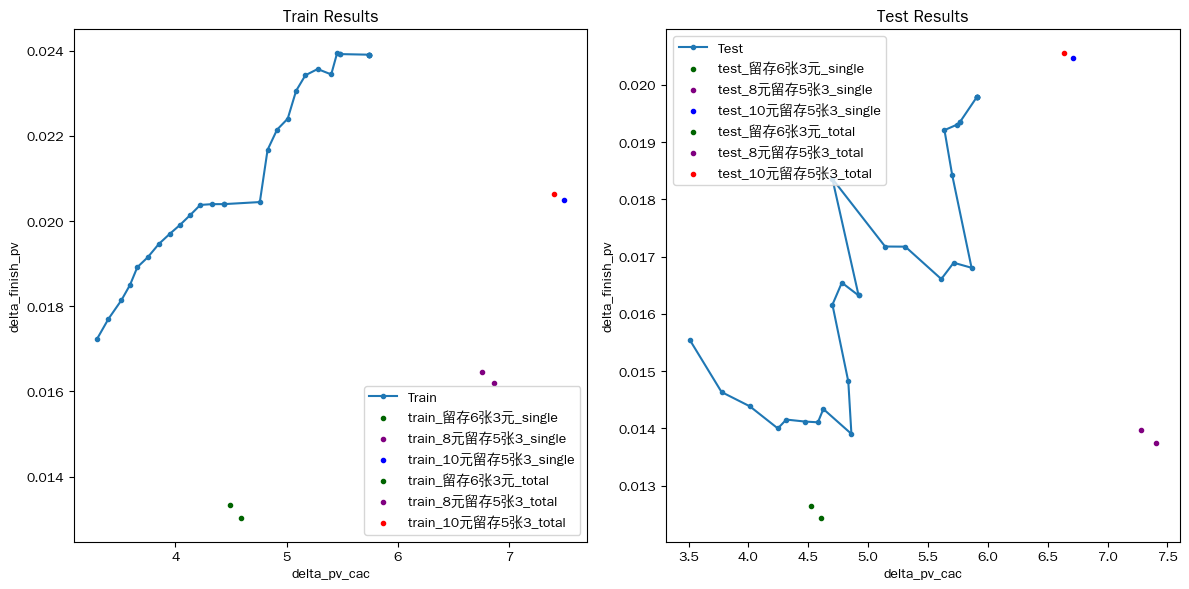


========== eeuen: running eeuen_v3 | s4 ==========
columns: ['cost_1', 'left1053_minus_left63', 'left853', 'left63']
all_columns: ['cost_1_per', 'left1053_minus_left63_per', 'left853_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06'

,cost_1_per,left1053_minus_left63_per,left853_per,left63_per,counts
11,0.1,0.1,0.2,0.2,12277
22,0.1,0.1,0.3,0.3,11818
4455,0.5,0.5,0.6,0.6,13736
5566,0.6,0.6,0.7,0.7,14574
6666,0.7,0.7,0.7,0.7,12584
6677,0.7,0.7,0.8,0.8,10455
7677,0.8,0.7,0.8,0.8,13653
7777,0.8,0.8,0.8,0.8,18874
8788,0.9,0.8,0.9,0.9,17685
8888,0.9,0.9,0.9,0.9,26089


['left1053_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_minus_left63_per,left63_per,counts
0,0.1,0.1,25420
1,0.1,0.2,10869
2,0.1,0.3,12390
10,0.2,0.1,17107
11,0.2,0.2,21922
12,0.2,0.3,24337
13,0.2,0.4,18661
20,0.3,0.1,12525
21,0.3,0.2,15641
22,0.3,0.3,16389


['left1053_minus_left63_per', 'left853_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage
['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,28378
1,0.2,22465
3,0.4,26309
4,0.5,22328
7,0.8,26234



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
2,0.3,18865
5,0.6,17268
6,0.7,13538
8,0.9,13251
9,1.0,13188


[39  2 16 21 15  5 20 29 11 41 24  0 10 38 37 27 12 25 28  6 35 40 26  7
 18  8  3 30 34 13 17 31 22  9 36 32  1 14 33 23  4 19]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   2009        1.0        3.0       3.748   
1              0   8元留存5张3   1848        8.0       44.0      17.402   
2              0      DS空白   5681       18.0       61.0       0.000   
3              0    留存6张3元   2739        3.0        6.0       4.391   
4              1  10元留存5张3   1540        1.0        1.0       3.168   
..           ...       ...    ...        ...        ...         ...   
163           40    留存6张3元   4913       64.0      172.0     307.665   
164           41  10元留存5张3   9294      171.0      440.0    1526.046   
165           41   8元留存5张3   9733      131.0      372.0     860.698   
166           41      DS空白  42409      427.0     1146.0       0.021   
167           41    留存6张3元  14674      238.0      627.0     899.718   

   

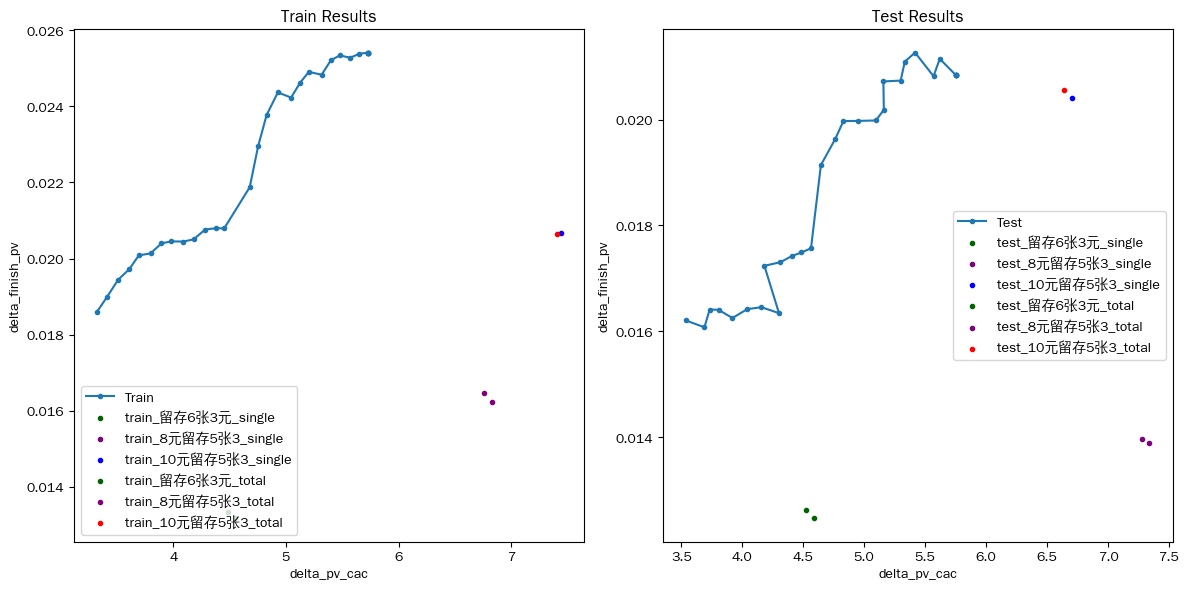


========== eeuen: running eeuen_v3 | s5 ==========
columns: ['cost_1', 'left1053', 'left63']
all_columns: ['cost_1_per', 'left1053_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']
(837501, 46) (843787, 46)
['cost_1_per', 'left1053

,cost_1_per,left1053_per,left63_per,counts
1,0.1,0.1,0.2,11440
11,0.1,0.2,0.2,11950
12,0.1,0.2,0.3,24387
23,0.1,0.3,0.4,10131
100,0.2,0.1,0.1,10519
111,0.2,0.2,0.2,11636
122,0.2,0.3,0.3,14857
123,0.2,0.3,0.4,12121
133,0.2,0.4,0.4,12096
200,0.3,0.1,0.1,10714


['left1053_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_per,left63_per,counts
0,0.1,0.1,41862
11,0.2,0.2,14031
21,0.3,0.2,14861
22,0.3,0.3,21715
32,0.4,0.3,10905
33,0.4,0.4,12589
34,0.4,0.5,15448
44,0.5,0.5,13947
45,0.5,0.6,12911
55,0.6,0.6,14159


['left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
0,0.1,20335
1,0.2,19256
2,0.3,11935
3,0.4,23771
4,0.5,14127
5,0.6,12573
6,0.7,20730
7,0.8,16495



============================== Final Small Combinations ==============================
Small Combinations (<10000 samples):


,left63_per,counts
8,0.9,9041
9,1.0,7526


[43 15  6 24 35 25 23 47 28  0 38 45 42 16 17 44 31 13 21 39 36 32 20 11
 41 33 22 19  5 30 46 26 18  8  7  9  2 12 34  1  3 37 14 40  4 27 10 29]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   2075        3.0        7.0       6.094   
1              0   8元留存5张3   1771        3.0        6.0       3.600   
2              0      DS空白   4964       12.0       47.0       0.000   
3              0    留存6张3元   2630        9.0       18.0      14.271   
4              1  10元留存5张3   1572        3.0        6.0      27.417   
..           ...       ...    ...        ...        ...         ...   
187           46    留存6张3元   3140       49.0      124.0     186.454   
188           47  10元留存5张3   2083       95.0      282.0     874.926   
189           47   8元留存5张3   2148       96.0      288.0     600.793   
190           47      DS空白   8958      243.0      578.0      30.000   
191           47    留存6张3元   3378      135.0      363.0  

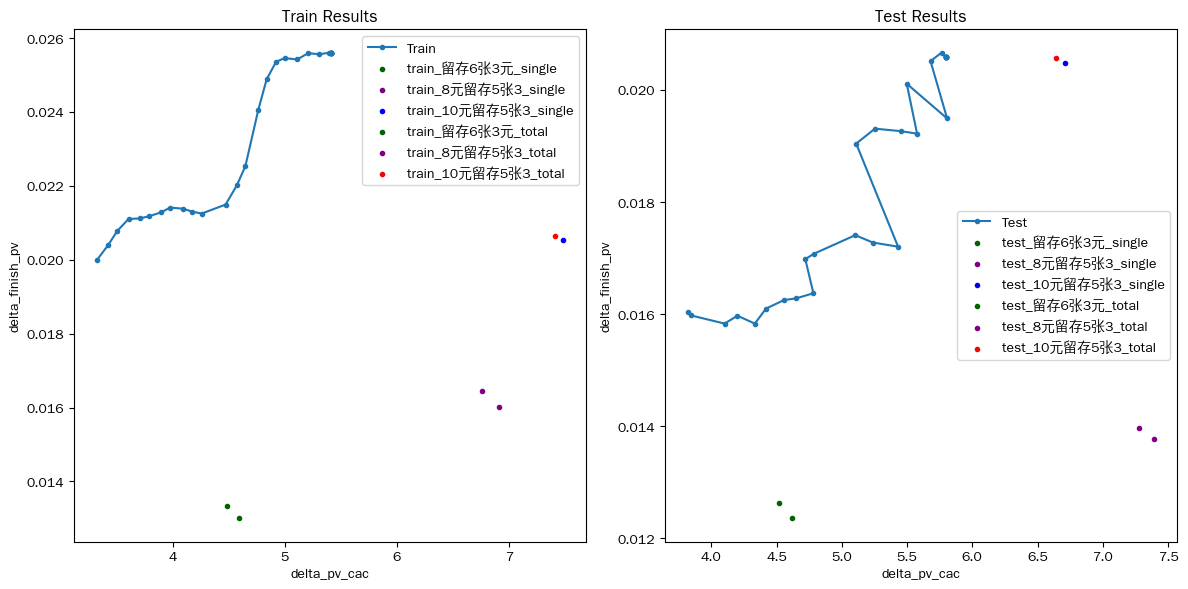

In [52]:
# 分别搜索euen/eeuen

euen_stage_results = run_stage_search(
    euen_scheme_dfs,
    euen_stage_configs,
    search_name='euen'
)

eeuen_stage_results = run_stage_search(
    eeuen_scheme_dfs,
    eeuen_stage_configs,
    search_name='eeuen'
)

stage_results = {}
stage_results.update(euen_stage_results)
stage_results.update(eeuen_stage_results)

In [55]:
# =========================
# 7. 汇总 train/test 仿真结果
# =========================

def build_stage_result_df(result_list, scheme_name, stage_name, data_type, search_name):
    df = pd.DataFrame(
        result_list,
        columns=[
            '约束cac',
            '实际增量cac',
            '实际增量cvr',
            '实际增量首单cvr',
            '留存频次',
        ]
    )
    df['search_name'] = search_name
    df['scheme'] = scheme_name
    df['stage_name'] = stage_name
    df['data_type'] = data_type
    return df


summary_list = []

for (scheme_name, stage_name), res in stage_results.items():
    summary_list.append(build_stage_result_df(res['train_list'], scheme_name, stage_name, 'train', res['search_name']))
    summary_list.append(build_stage_result_df(res['test_list'], scheme_name, stage_name, 'test', res['search_name']))

stage_summary_df = pd.concat(summary_list, ignore_index=True)

stage_summary_df[
    ['search_name', 'scheme', 'stage_name', 'data_type', '约束cac', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']
].head(10)

,search_name,scheme,stage_name,data_type,约束cac,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
0,euen,euen_v2,s1,train,3.5,3.296566,0.016622,0.005885,2.824695
1,euen,euen_v2,s1,train,3.6,3.390304,0.017142,0.005945,2.883638
2,euen,euen_v2,s1,train,3.7,3.491802,0.017847,0.006138,2.907647
3,euen,euen_v2,s1,train,3.8,3.579752,0.018362,0.006325,2.903278
4,euen,euen_v2,s1,train,3.9,3.686996,0.018627,0.006489,2.870554
5,euen,euen_v2,s1,train,4.0,3.787625,0.018874,0.006749,2.796709
6,euen,euen_v2,s1,train,4.1,3.879575,0.019529,0.006596,2.960801
7,euen,euen_v2,s1,train,4.2,3.982961,0.020048,0.006792,2.951578
8,euen,euen_v2,s1,train,4.3,4.093110,0.020295,0.007060,2.874648
9,euen,euen_v2,s1,train,4.4,4.206901,0.020475,0.006861,2.984204


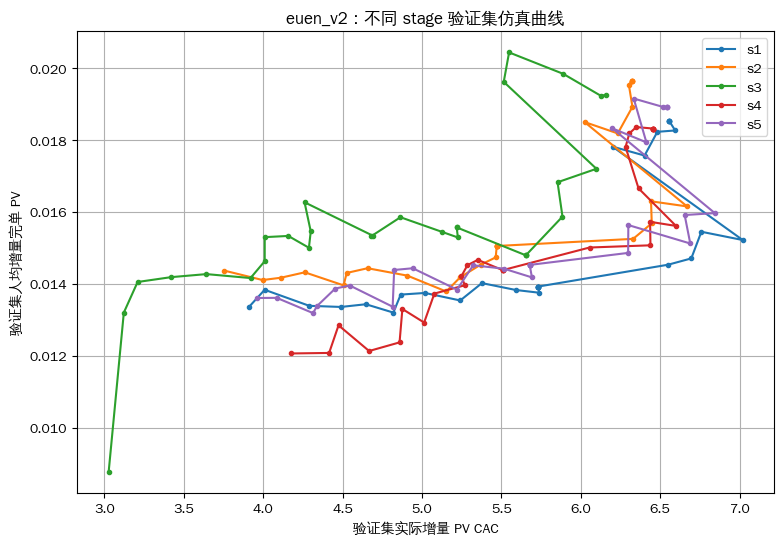

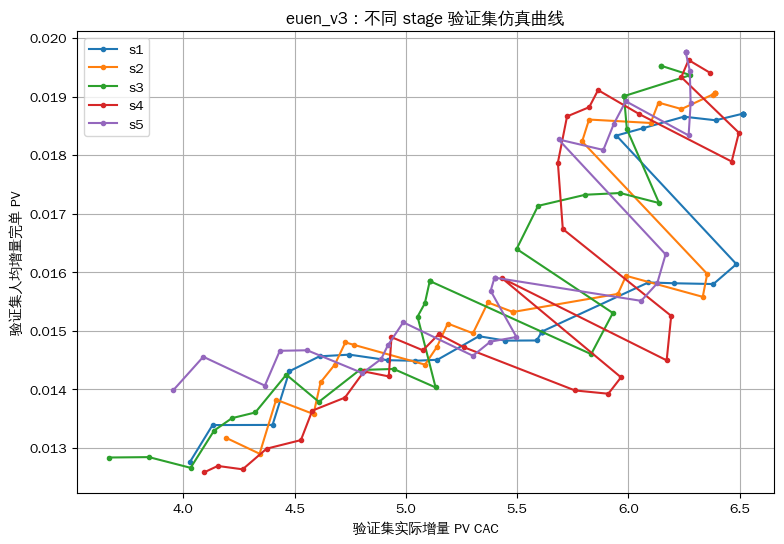

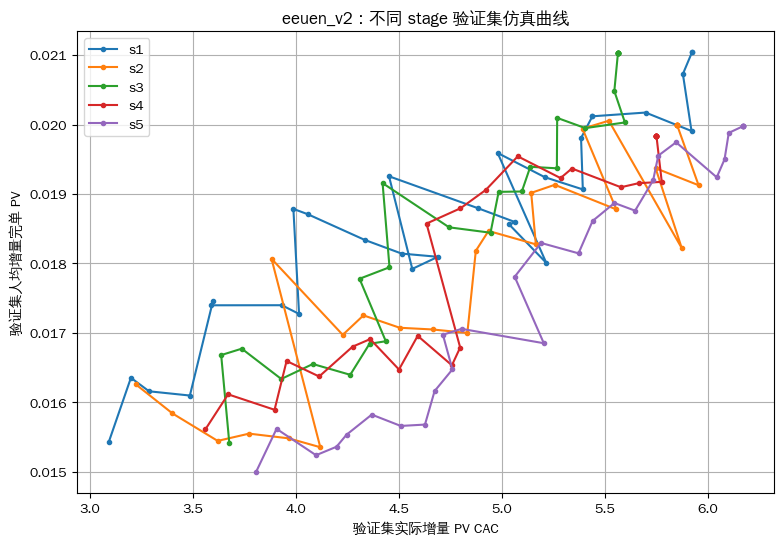

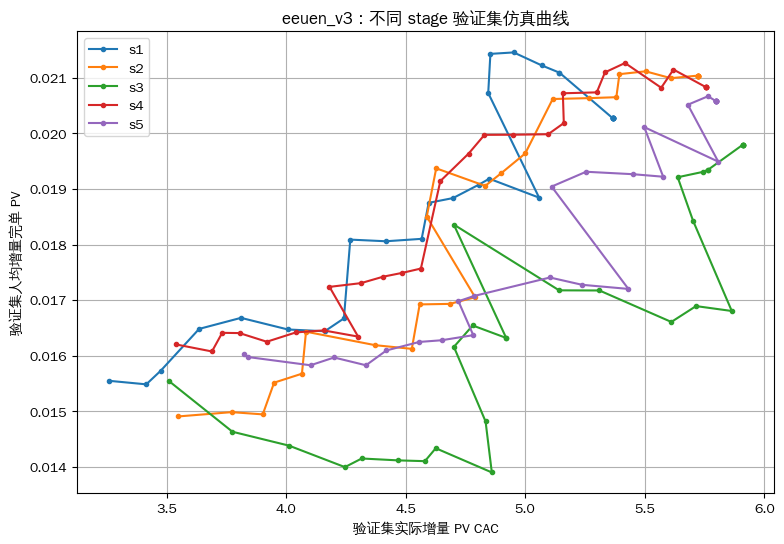

In [60]:

# 8. 一个模型一个图：不同 stage 下验证集仿真曲线

for scheme_name in ['euen_v2', 'euen_v3', 'eeuen_v2', 'eeuen_v3']:
    plt.figure(figsize=(9, 6))

    stage_names = (
        stage_summary_df[
            (stage_summary_df['scheme'] == scheme_name) &
            (stage_summary_df['data_type'] == 'test')
        ]['stage_name']
        .drop_duplicates()
        .tolist()
    )

    for stage_name in stage_names:
        plot_df = stage_summary_df[
            (stage_summary_df['scheme'] == scheme_name) &
            (stage_summary_df['stage_name'] == stage_name) &
            (stage_summary_df['data_type'] == 'test')
        ].replace([np.inf, -np.inf], np.nan).dropna(
            subset=['实际增量cac', '实际增量cvr']
        ).sort_values('约束cac')

        # ).sort_values('实际增量cac')

        plt.plot(
            plot_df['实际增量cac'],
            plot_df['实际增量cvr'],
            marker='.',
            label=stage_name
        )

    plt.xlabel('验证集实际增量 PV CAC')
    plt.ylabel('验证集人均增量完单 PV')
    plt.title(f'{scheme_name}：不同 stage 验证集仿真曲线')
    plt.legend()
    plt.grid(True)
    plt.show()

In [62]:
# 最佳参数

best_stage_map = {
    'euen_v2': 's3',
    'euen_v3': 's5',
    'eeuen_v2': 's1',
    'eeuen_v3': 's4',
}

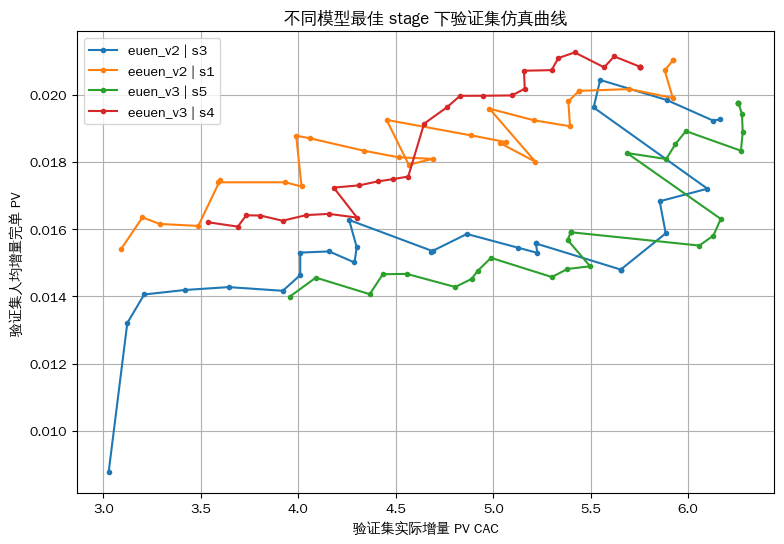

In [63]:
best_stage_summary_df = pd.concat([
    stage_summary_df[
        (stage_summary_df['scheme'] == scheme) &
        (stage_summary_df['stage_name'] == stage_name) &
        (stage_summary_df['data_type'] == 'test')
    ]
    for scheme, stage_name in best_stage_map.items()
], ignore_index=True)

plt.figure(figsize=(9, 6))

for scheme_name in ['euen_v2', 'eeuen_v2', 'euen_v3', 'eeuen_v3']:
    plot_df = best_stage_summary_df[
        best_stage_summary_df['scheme'] == scheme_name
    ].replace([np.inf, -np.inf], np.nan).dropna(
        subset=['实际增量cac', '实际增量cvr']
   # ).sort_values('实际增量cac')
    ).sort_values('约束cac')

    plt.plot(
        plot_df['实际增量cac'],
        plot_df['实际增量cvr'],
        marker='.',
        label=f"{scheme_name} | {best_stage_map[scheme_name]}"
    )

plt.xlabel('验证集实际增量 PV CAC')
plt.ylabel('验证集人均增量完单 PV')
plt.title('不同模型最佳 stage 下验证集仿真曲线')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:

# 7. 汇总 train/test 仿真结果


def build_stage_result_df(result_list, scheme_name, stage_name, data_type, search_name):
    df = pd.DataFrame(
        result_list,
        columns=[
            '约束cac',
            '实际增量cac',
            '实际增量cvr',
            '实际增量首单cvr',
            '留存频次',
        ]
    )
    df['search_name'] = search_name
    df['scheme'] = scheme_name
    df['stage_name'] = stage_name
    df['data_type'] = data_type
    return df


summary_list = []

for (scheme_name, stage_name), res in stage_results.items():
    summary_list.append(build_stage_result_df(res['train_list'], scheme_name, stage_name, 'train', res['search_name']))
    summary_list.append(build_stage_result_df(res['test_list'], scheme_name, stage_name, 'test', res['search_name']))

stage_summary_df = pd.concat(summary_list, ignore_index=True)

stage_summary_df[
    ['search_name', 'scheme', 'stage_name', 'data_type', '约束cac', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']
].head()

In [ ]:

#8. 一个模型一个图：不同 stage 下验证集仿真曲线


for scheme_name in ['euen_v2', 'euen_v3', 'eeuen_v2', 'eeuen_v3']:
    plt.figure(figsize=(9, 6))

    stage_names = (
        stage_summary_df[
            (stage_summary_df['scheme'] == scheme_name) &
            (stage_summary_df['data_type'] == 'test')
        ]['stage_name']
        .drop_duplicates()
        .tolist()
    )

    for stage_name in stage_names:
        plot_df = stage_summary_df[
            (stage_summary_df['scheme'] == scheme_name) &
            (stage_summary_df['stage_name'] == stage_name) &
            (stage_summary_df['data_type'] == 'test')
        ].replace([np.inf, -np.inf], np.nan).dropna(
            subset=['实际增量cac', '实际增量cvr']
        ).sort_values('实际增量cac')

        plt.plot(
            plot_df['实际增量cac'],
            plot_df['实际增量cvr'],
            marker='.',
            label=stage_name
        )

    plt.xlabel('验证集实际增量 PV CAC')
    plt.ylabel('验证集人均增量完单 PV')
    plt.title(f'{scheme_name}：不同 stage 验证集仿真曲线')
    plt.legend()
    plt.grid(True)
    plt.show()

In [30]:

# 5. 汇总 train/test 仿真结果


def build_stage_result_df(result_list, scheme_name, stage_name, data_type):
    df = pd.DataFrame(
        result_list,
        columns=[
            '约束cac',
            '实际增量cac',
            '实际增量cvr',
            '实际增量首单cvr',
            '留存频次',
        ]
    )
    df['scheme'] = scheme_name
    df['stage_name'] = stage_name
    df['data_type'] = data_type
    return df


summary_list = []

for (scheme_name, stage_name), res in stage_results.items():
    summary_list.append(build_stage_result_df(res['train_list'], scheme_name, stage_name, 'train'))
    summary_list.append(build_stage_result_df(res['test_list'], scheme_name, stage_name, 'test'))

stage_summary_df = pd.concat(summary_list, ignore_index=True)

stage_summary_df[
    ['scheme', 'stage_name', 'data_type', '约束cac', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']
]

,scheme,stage_name,data_type,约束cac,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
0,baseline,s1,train,6.5,6.305133,0.019712,0.007275,2.709688
1,baseline,s1,train,6.6,6.433638,0.019597,0.007226,2.711842
2,baseline,s1,train,6.7,6.557600,0.020235,0.007215,2.804683
3,baseline,s1,train,6.8,6.712413,0.021120,0.007082,2.982405
4,baseline,s1,train,6.9,6.804970,0.022010,0.007525,2.924794
...,...,...,...,...,...,...,...,...
595,replace_order,s4,test,8.5,7.263132,0.024865,0.008992,2.765205
596,replace_order,s4,test,8.6,7.263132,0.024865,0.008992,2.765205
597,replace_order,s4,test,8.7,7.263132,0.024865,0.008992,2.765205
598,replace_order,s4,test,8.8,7.263132,0.024865,0.008992,2.765205


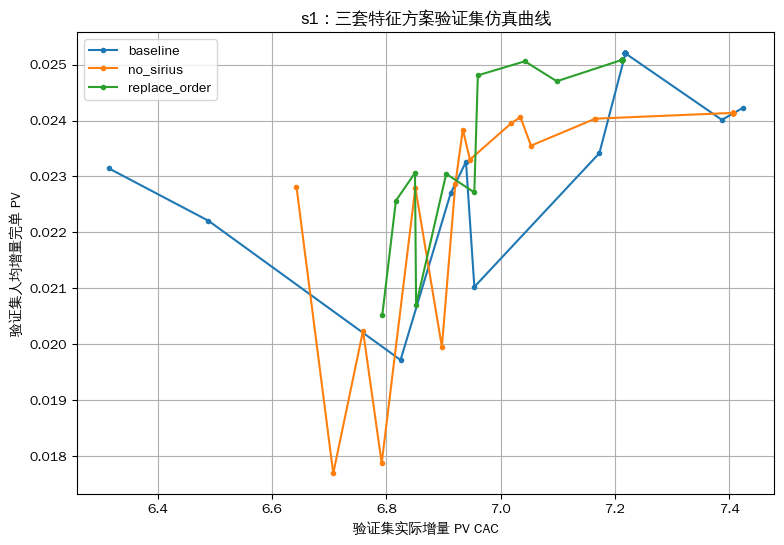

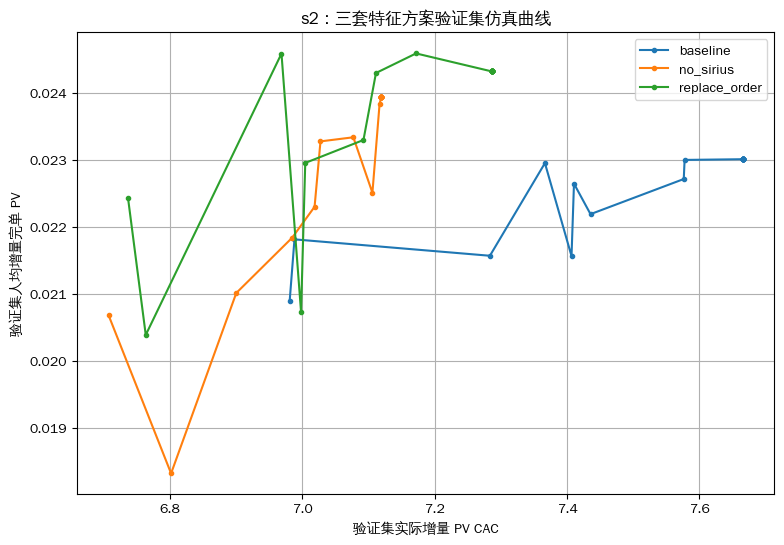

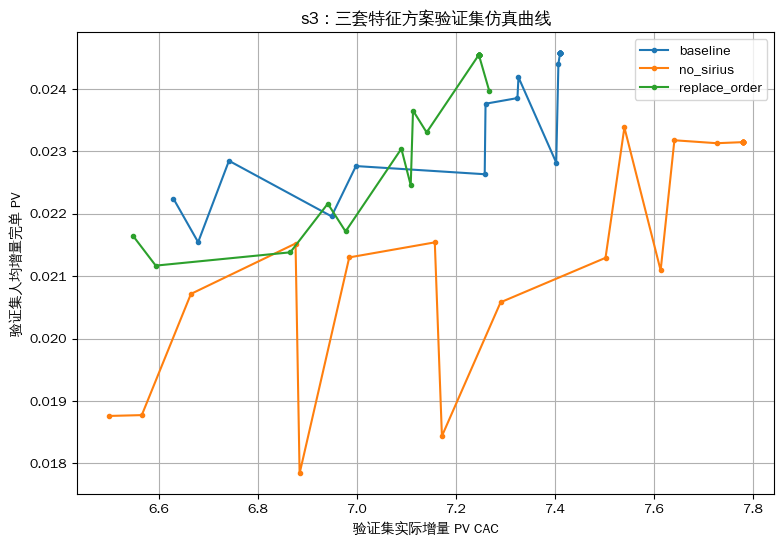

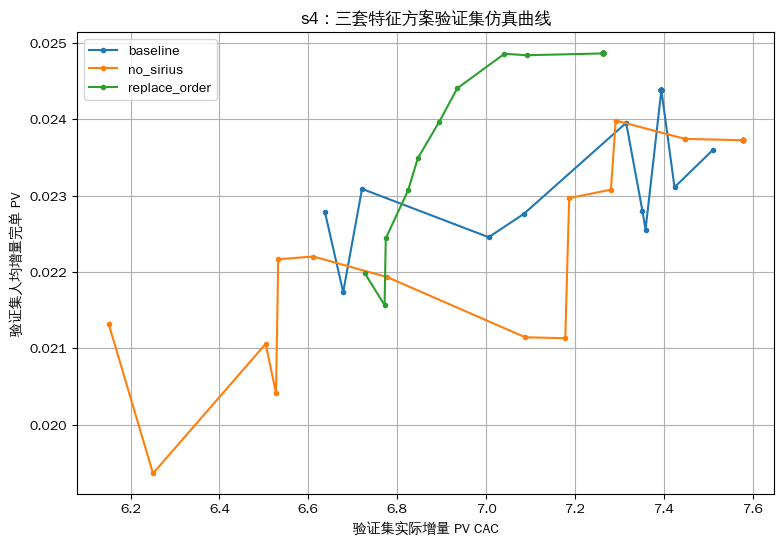

In [40]:

# 6. 一个图对应一个 stage，图里放三个特征方案


for stage_name in stage_configs.keys():
    plt.figure(figsize=(9, 6))

    for scheme_name in scheme_dfs.keys():
        plot_df = stage_summary_df[
            (stage_summary_df['stage_name'] == stage_name) &
            (stage_summary_df['scheme'] == scheme_name) &
            (stage_summary_df['data_type'] == 'test')
       #  ].sort_values('约束cac')
        ].sort_values('实际增量cac')

        plt.plot(
            plot_df['实际增量cac'],
            plot_df['实际增量cvr'],
            marker='.',
            label=scheme_name
        )

    plt.xlabel('验证集实际增量 PV CAC')
    plt.ylabel('验证集人均增量完单 PV')
    plt.title(f'{stage_name}：三套特征方案验证集仿真曲线')
    plt.legend()
    plt.grid(True)
    plt.show()

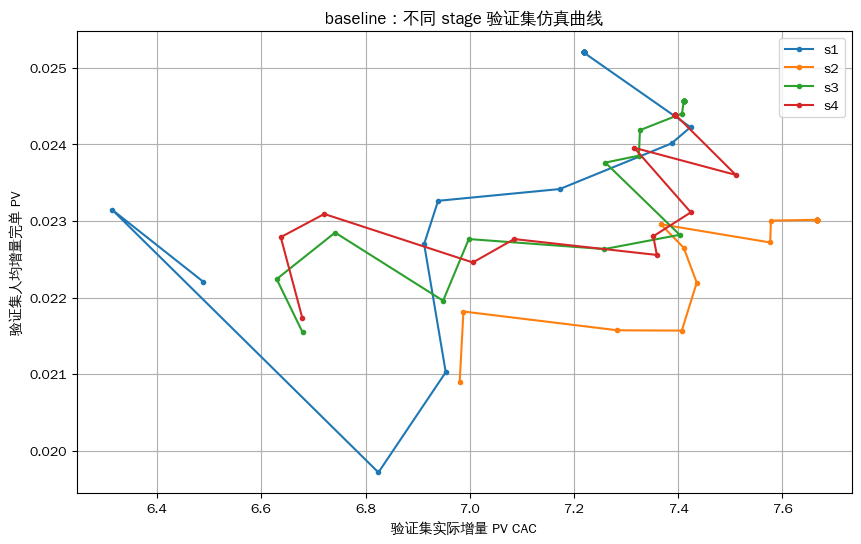

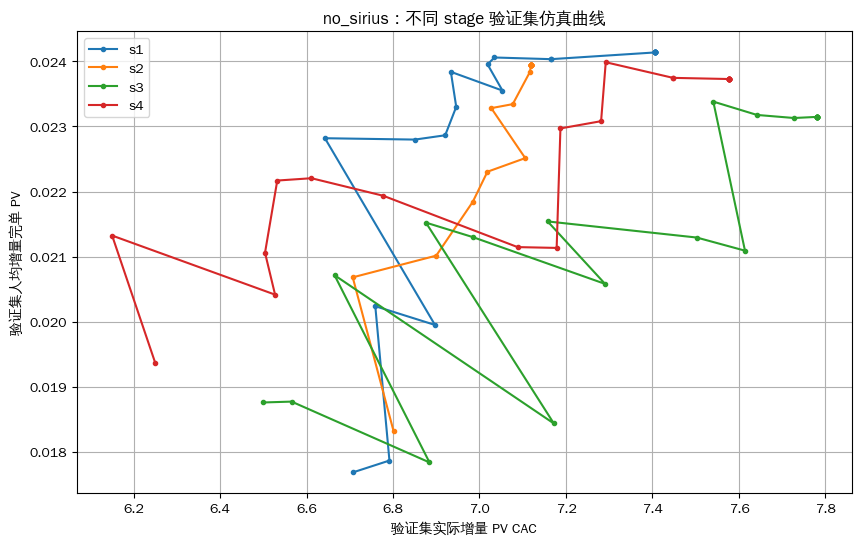

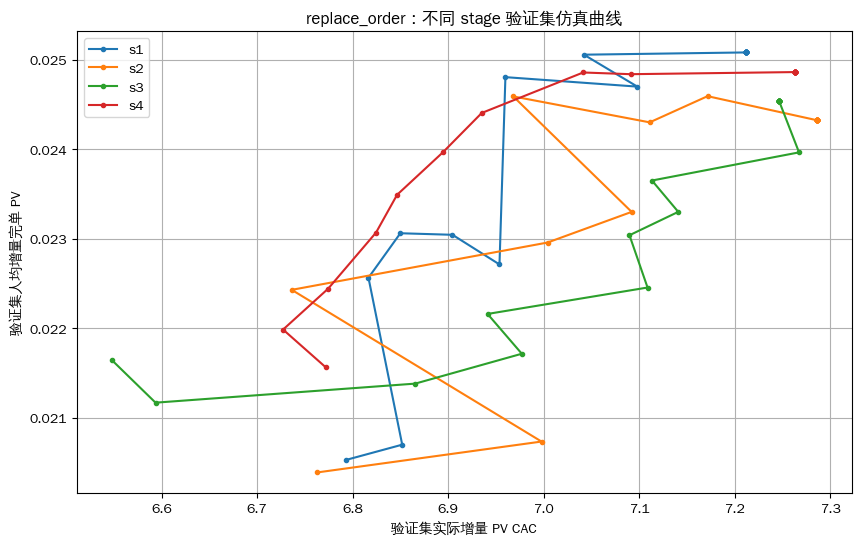

In [32]:

#7. 一个图对应一个方案，图里放不同 stage
for scheme_name in scheme_dfs.keys():
    plt.figure(figsize=(10, 6))

    for stage_name in stage_configs.keys():
        plot_df = stage_summary_df[
            (stage_summary_df['scheme'] == scheme_name) &
            (stage_summary_df['stage_name'] == stage_name) &
            (stage_summary_df['data_type'] == 'test')
        ].sort_values('约束cac')

        plt.plot(
            plot_df['实际增量cac'],
            plot_df['实际增量cvr'],
            marker='.',
            label=stage_name
        )

    plt.xlabel('验证集实际增量 PV CAC')
    plt.ylabel('验证集人均增量完单 PV')
    plt.title(f'{scheme_name}：不同 stage 验证集仿真曲线')
    plt.legend()
    plt.grid(True)
    plt.show()

In [33]:
test_by_set_cac_df = (
    stage_summary_df[
        (stage_summary_df['stage_name'] == 's1') &
        (stage_summary_df['data_type'] == 'test')
    ]
    .sort_values(['约束cac', 'scheme'])
    [['scheme', 'stage_name', '约束cac', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']]
)

test_by_set_cac_df

,scheme,stage_name,约束cac,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
25,baseline,s1,6.5,6.488642,0.022206,0.007951,2.792948
225,no_sirius,s1,6.5,6.706982,0.017686,0.006509,2.717034
425,replace_order,s1,6.5,6.792910,0.020527,0.007546,2.720128
26,baseline,s1,6.6,6.313836,0.023146,0.008118,2.851237
226,no_sirius,s1,6.6,6.791766,0.017868,0.006681,2.674431
...,...,...,...,...,...,...,...
248,no_sirius,s1,8.8,7.406453,0.024137,0.008587,2.810962
448,replace_order,s1,8.8,7.212253,0.025085,0.009033,2.776923
49,baseline,s1,8.9,7.218402,0.025201,0.008876,2.839337
249,no_sirius,s1,8.9,7.406453,0.024137,0.008587,2.810962


In [34]:
# 每个约束cac下哪个方案最好
best_each_set_cac = (
    test_by_set_cac_df
    .sort_values(['约束cac', '实际增量cvr'], ascending=[True, False])
    .groupby('约束cac')
    .head(1) )

best_each_set_cac[
    ['约束cac', 'scheme', 'stage_name', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']
]

,约束cac,scheme,stage_name,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
25,6.5,baseline,s1,6.488642,0.022206,0.007951,2.792948
26,6.6,baseline,s1,6.313836,0.023146,0.008118,2.851237
427,6.7,replace_order,s1,6.816640,0.022566,0.008182,2.757959
428,6.8,replace_order,s1,6.850040,0.023063,0.008405,2.743803
429,6.9,replace_order,s1,6.904631,0.023046,0.008481,2.717310
30,7.0,baseline,s1,6.939290,0.023263,0.008232,2.826032
431,7.1,replace_order,s1,6.960054,0.024809,0.008759,2.832218
432,7.2,replace_order,s1,7.098209,0.024703,0.008872,2.784351
433,7.3,replace_order,s1,7.042277,0.025060,0.008963,2.795894
34,7.4,baseline,s1,7.218402,0.025201,0.008876,2.839337


In [35]:
test_by_set_cac_df = (
    stage_summary_df[
        (stage_summary_df['stage_name'] == 's4') &
        (stage_summary_df['data_type'] == 'test')
    ]
    .sort_values(['约束cac', 'scheme'])
    [['scheme', 'stage_name', '约束cac', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']]
)

test_by_set_cac_df

# 每个约束cac下哪个方案最好
best_each_set_cac = (
    test_by_set_cac_df
    .sort_values(['约束cac', '实际增量cvr'], ascending=[True, False])
    .groupby('约束cac')
    .head(1)
)

best_each_set_cac[
    ['约束cac', 'scheme', 'stage_name', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']
]

,约束cac,scheme,stage_name,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
175,6.5,baseline,s4,6.678531,0.021738,0.007934,2.739852
176,6.6,baseline,s4,6.637381,0.022788,0.008151,2.795755
177,6.7,baseline,s4,6.720920,0.023091,0.008280,2.788689
578,6.8,replace_order,s4,6.824581,0.023071,0.008150,2.830826
579,6.9,replace_order,s4,6.846626,0.023493,0.008338,2.817456
580,7.0,replace_order,s4,6.894467,0.023967,0.008463,2.831929
581,7.1,replace_order,s4,6.935296,0.024408,0.008657,2.819484
582,7.2,replace_order,s4,7.041463,0.024861,0.008846,2.810373
583,7.3,replace_order,s4,7.091229,0.024842,0.008922,2.784184
584,7.4,replace_order,s4,7.263132,0.024865,0.008992,2.765205


In [37]:
test_by_set_cac_df = (
    stage_summary_df[
        (stage_summary_df['stage_name'] == 's3') &
        (stage_summary_df['data_type'] == 'test')
    ]
    .sort_values(['约束cac', 'scheme'])
    [['scheme', 'stage_name', '约束cac', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']]
)

test_by_set_cac_df

# 每个约束cac下哪个方案最好
best_each_set_cac = (
    test_by_set_cac_df
    .sort_values(['约束cac', '实际增量cvr'], ascending=[True, False])
    .groupby('约束cac')
    .head(1)
)

best_each_set_cac[
    ['约束cac', 'scheme', 'stage_name', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']
]

,约束cac,scheme,stage_name,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
525,6.5,replace_order,s3,6.548206,0.021642,0.008222,2.632207
126,6.6,baseline,s3,6.629516,0.022240,0.008008,2.777392
127,6.7,baseline,s3,6.741640,0.022848,0.008185,2.791445
128,6.8,baseline,s3,6.948896,0.021958,0.007897,2.780478
129,6.9,baseline,s3,6.998205,0.022763,0.008171,2.785744
130,7.0,baseline,s3,7.258385,0.022633,0.008188,2.764054
531,7.1,replace_order,s3,7.089969,0.023041,0.008584,2.684029
132,7.2,baseline,s3,7.260061,0.023762,0.008605,2.761534
133,7.3,baseline,s3,7.324514,0.023853,0.008758,2.723396
134,7.4,baseline,s3,7.326597,0.024186,0.008856,2.730965


In [49]:
show_cols = [
    'scheme',
    'stage_name',
    'data_type',
    '约束cac',
    '实际增量cac',
    '实际增量cvr',
    '实际增量首单cvr',
    '留存频次',
]

baseline_table = (
    stage_summary_df[
        (stage_summary_df['scheme'] == 'baseline') &
        (stage_summary_df['data_type'] == 'test')&
        (stage_summary_df['stage_name'] == 's1')
    ]
    .sort_values(['stage_name', '约束cac'])
    [show_cols]
)

no_sirius_table = (
    stage_summary_df[
        (stage_summary_df['scheme'] == 'no_sirius') &
        (stage_summary_df['data_type'] == 'test')&
        (stage_summary_df['stage_name'] == 's1')
    ]
    .sort_values(['stage_name', '约束cac'])
    [show_cols]
)

replace_order_table = (
    stage_summary_df[
        (stage_summary_df['scheme'] == 'replace_order') &
        (stage_summary_df['data_type'] == 'test')&
        (stage_summary_df['stage_name'] == 's1')
    ]
    .sort_values(['stage_name', '约束cac'])
    [show_cols]
)

In [53]:
baseline_table
# baseline_table.to_excel('baseline_table.xlsx', index=False)

,scheme,stage_name,data_type,约束cac,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
25,baseline,s1,test,6.5,6.488642,0.022206,0.007951,2.792948
26,baseline,s1,test,6.6,6.313836,0.023146,0.008118,2.851237
27,baseline,s1,test,6.7,6.824765,0.019716,0.007156,2.755114
28,baseline,s1,test,6.8,6.953936,0.021024,0.007650,2.748336
29,baseline,s1,test,6.9,6.912476,0.022698,0.008113,2.797620
30,baseline,s1,test,7.0,6.939290,0.023263,0.008232,2.826032
31,baseline,s1,test,7.1,7.172724,0.023416,0.008408,2.784886
32,baseline,s1,test,7.2,7.387116,0.024012,0.008519,2.818618
33,baseline,s1,test,7.3,7.423570,0.024225,0.008693,2.786538
34,baseline,s1,test,7.4,7.218402,0.025201,0.008876,2.839337


In [54]:
no_sirius_table
# no_sirius_table.to_excel('no_sirius_table.xlsx', index=False)

,scheme,stage_name,data_type,约束cac,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
225,no_sirius,s1,test,6.5,6.706982,0.017686,0.006509,2.717034
226,no_sirius,s1,test,6.6,6.791766,0.017868,0.006681,2.674431
227,no_sirius,s1,test,6.7,6.759084,0.020239,0.007298,2.773338
228,no_sirius,s1,test,6.8,6.897084,0.019951,0.007213,2.765862
229,no_sirius,s1,test,6.9,6.642589,0.022819,0.008012,2.848165
230,no_sirius,s1,test,7.0,6.850671,0.022798,0.008128,2.804873
231,no_sirius,s1,test,7.1,6.920665,0.022864,0.008172,2.797710
232,no_sirius,s1,test,7.2,6.946206,0.023301,0.008359,2.787522
233,no_sirius,s1,test,7.3,6.933767,0.023839,0.008415,2.832986
234,no_sirius,s1,test,7.4,7.053112,0.023551,0.008267,2.848819


In [55]:
replace_order_table
# no_sirius_table.to_excel('replace_order_table.xlsx', index=False)

,scheme,stage_name,data_type,约束cac,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
425,replace_order,s1,test,6.5,6.792910,0.020527,0.007546,2.720128
426,replace_order,s1,test,6.6,6.851983,0.020699,0.007703,2.687179
427,replace_order,s1,test,6.7,6.816640,0.022566,0.008182,2.757959
428,replace_order,s1,test,6.8,6.850040,0.023063,0.008405,2.743803
429,replace_order,s1,test,6.9,6.904631,0.023046,0.008481,2.717310
430,replace_order,s1,test,7.0,6.953842,0.022714,0.008102,2.803618
431,replace_order,s1,test,7.1,6.960054,0.024809,0.008759,2.832218
432,replace_order,s1,test,7.2,7.098209,0.024703,0.008872,2.784351
433,replace_order,s1,test,7.3,7.042277,0.025060,0.008963,2.795894
434,replace_order,s1,test,7.4,7.212253,0.025085,0.009033,2.776923
